In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Ellipse
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import ndimage, signal
from scipy.ndimage import gaussian_filter
from pathlib import Path
import sys

# Add src to path if running from notebooks directory
notebook_dir = Path('.').resolve()
if notebook_dir.name == 'vision':
    sys.path.append(str(notebook_dir.parent.parent))
else:
    sys.path.append(str(notebook_dir.parent))

# Import the actual DendriteConv2d from the package
from dendritic_modeling.networks.layers.dendritic_conv2d import DendriteConv2d
from dendritic_modeling.networks.architectures.excitation_inhibition import DendriNet

# Set up visualization
plt.style.use('default')
torch.manual_seed(42)
np.random.seed(42)

# Custom colormap for receptive fields (red-white-blue)
colors = [(0, 0, 1), (1, 1, 1), (1, 0, 0)]  # Blue -> White -> Red
n_bins = 100
cmap_name = 'bwr_centered'
rwb_cmap = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)


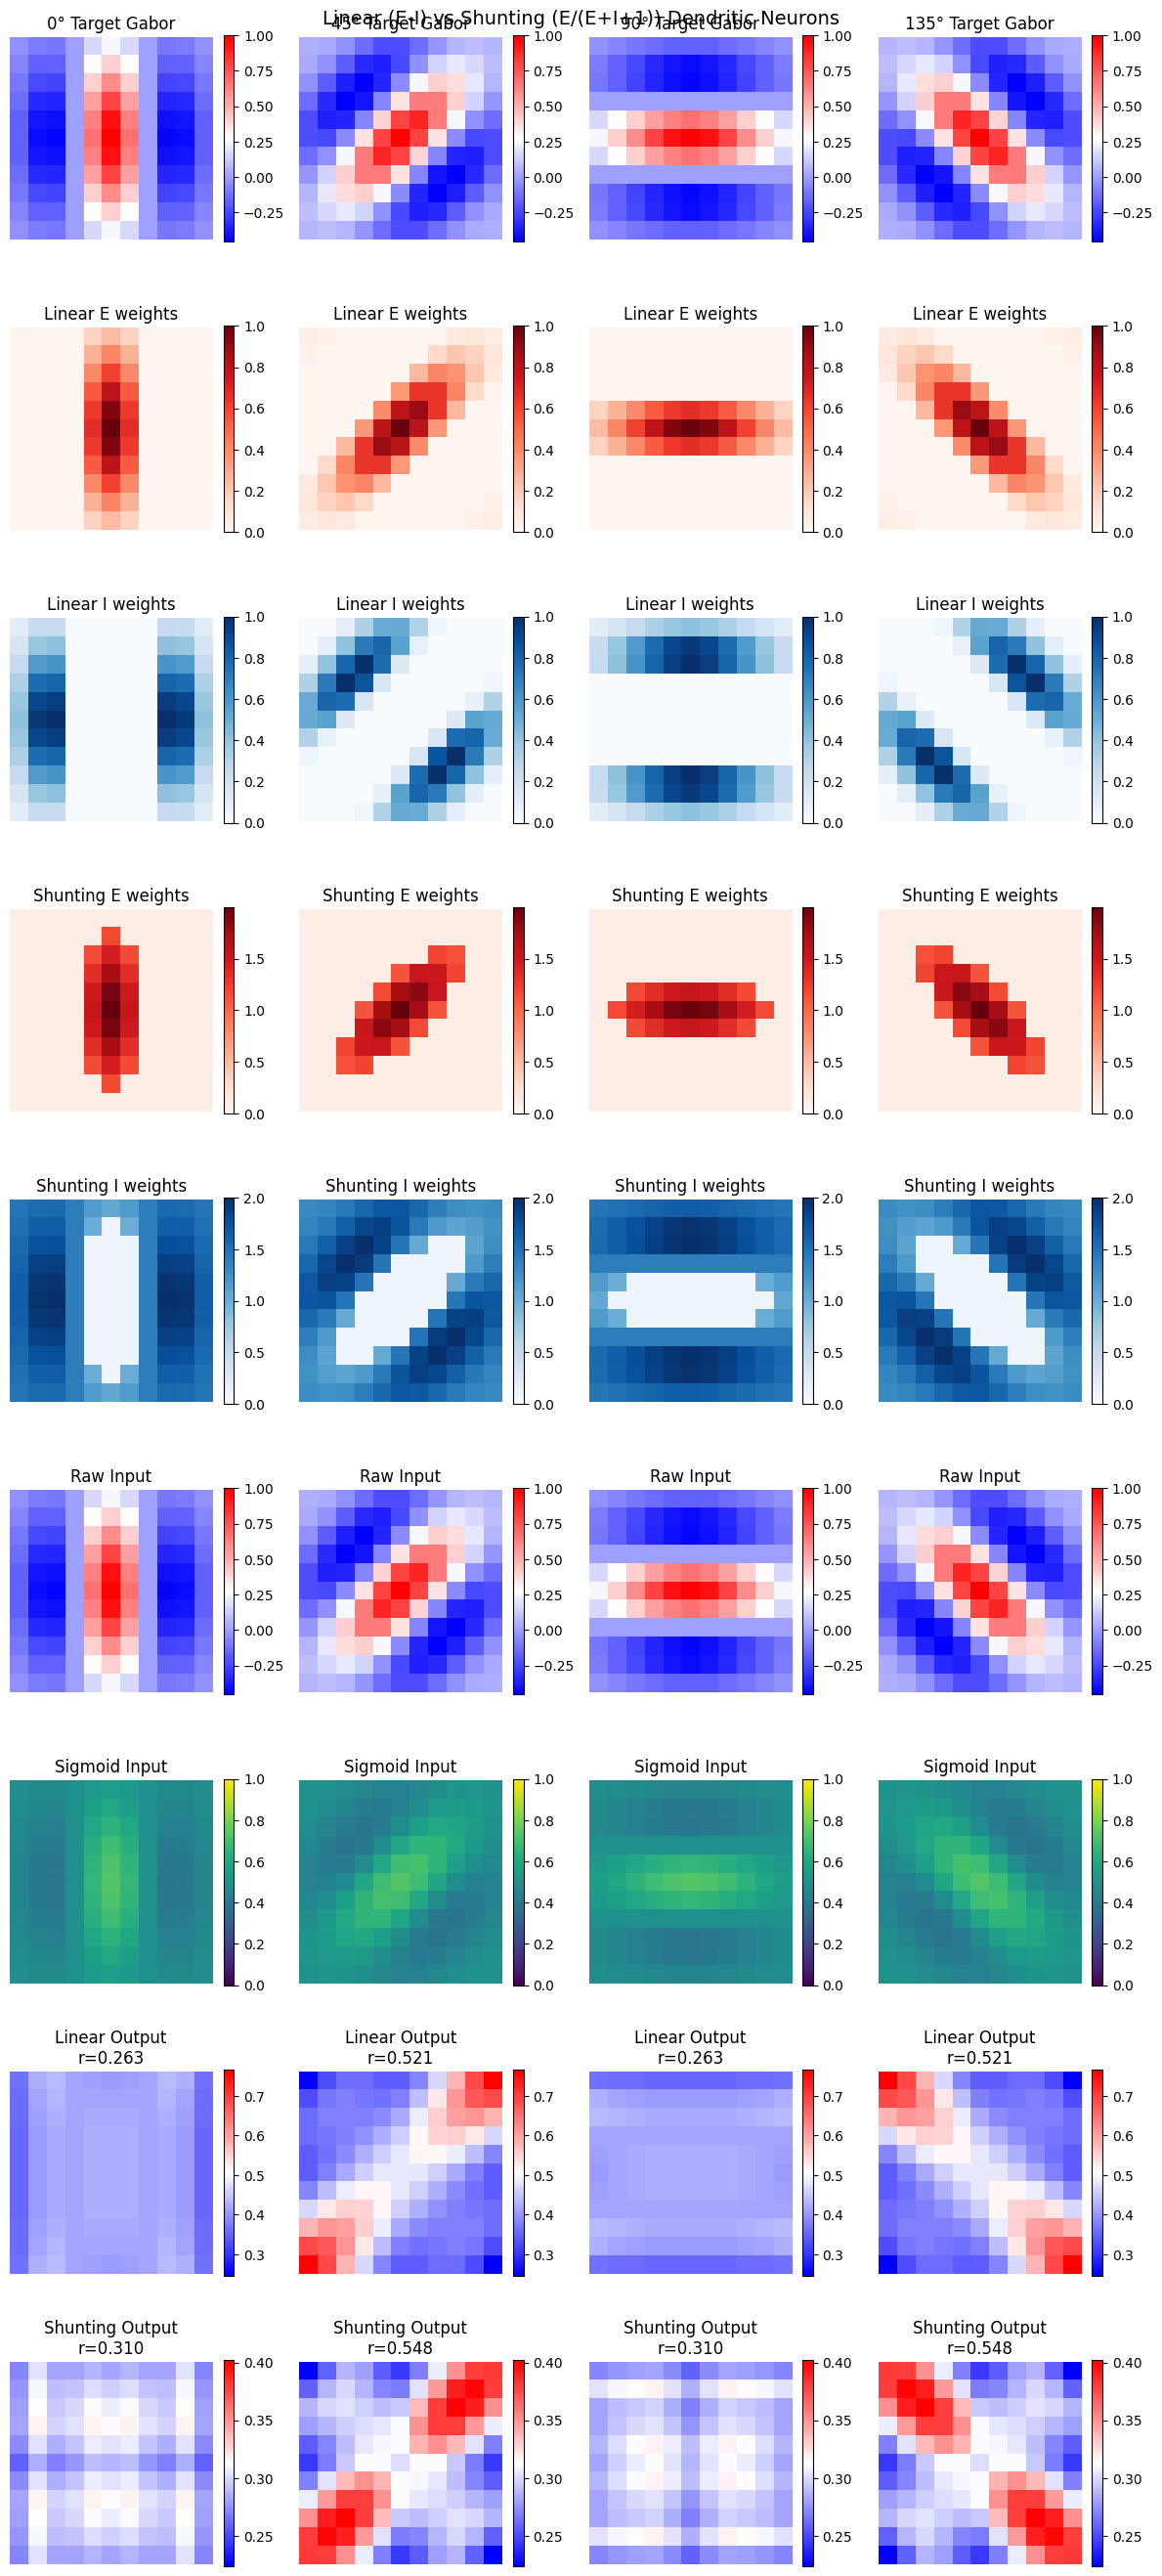

Comparison of Linear vs Shunting Dendritic Neurons:
  0° orientation:
    Linear (E-I): correlation = 0.263
    Shunting (E/(E+I+1)): correlation = 0.310
    Linear output range: [0.353, 0.435]
    Shunting output range: [0.258, 0.317]
  45° orientation:
    Linear (E-I): correlation = 0.521
    Shunting (E/(E+I+1)): correlation = 0.548
    Linear output range: [0.246, 0.766]
    Shunting output range: [0.224, 0.402]
  90° orientation:
    Linear (E-I): correlation = 0.263
    Shunting (E/(E+I+1)): correlation = 0.310
    Linear output range: [0.353, 0.435]
    Shunting output range: [0.258, 0.317]
  135° orientation:
    Linear (E-I): correlation = 0.521
    Shunting (E/(E+I+1)): correlation = 0.548
    Linear output range: [0.246, 0.766]
    Shunting output range: [0.224, 0.402]


In [25]:
def create_gabor_filter(size, wavelength, orientation, phase, sigma, aspect_ratio=1.0):
    """Create a Gabor filter kernel."""
    x = np.arange(size) - size // 2
    y = np.arange(size) - size // 2
    X, Y = np.meshgrid(x, y)
    
    # Rotate coordinates
    theta = np.deg2rad(orientation)
    X_rot = X * np.cos(theta) + Y * np.sin(theta)
    Y_rot = -X * np.sin(theta) + Y * np.cos(theta)
    
    # Gabor function
    gaussian = np.exp(-(X_rot**2 + (Y_rot/aspect_ratio)**2) / (2 * sigma**2))
    sinusoid = np.cos(2 * np.pi * X_rot / wavelength + phase)
    gabor = gaussian * sinusoid
    
    return gabor

def solve_linear_weights(target_gabor):
    """
    Solve for E and I weights for linear neuron: V_out = E - I
    Simple approach: E gets positive parts, I gets negative parts (inverted)
    """
    E_weights = np.maximum(target_gabor, 0)
    I_weights = np.maximum(-target_gabor, 0)
    
    # Normalize to reasonable ranges
    if E_weights.max() > 0:
        E_weights = E_weights / E_weights.max()
    if I_weights.max() > 0:
        I_weights = I_weights / I_weights.max()
    
    return E_weights, I_weights

def solve_shunting_weights(target_gabor):
    """
    Solve for E and I weights for shunting neuron: V_out = E / (E + I + 1)
    
    For positive target values: need E > I
    For negative target values: need I > E (to make fraction small)
    """
    E_weights = np.zeros_like(target_gabor)
    I_weights = np.zeros_like(target_gabor)
    
    # Normalize target to [0, 1] range for shunting output
    target_norm = (target_gabor - target_gabor.min()) / (target_gabor.max() - target_gabor.min() + 1e-8)
    
    for i in range(target_gabor.shape[0]):
        for j in range(target_gabor.shape[1]):
            target_val = target_norm[i, j]
            
            if target_val > 0.5:  # Want high output
                # Set E high, I low
                E_weights[i, j] = target_val * 2.0  # Scale up
                I_weights[i, j] = 0.1  # Small baseline
            else:  # Want low output
                # Set I high, E low
                E_weights[i, j] = 0.1  # Small baseline
                I_weights[i, j] = (1 - target_val) * 2.0  # Scale up
    
    return E_weights, I_weights

def create_dendritic_gabor_neuron_linear(kernel_size=11, wavelength=8, orientation=0, sigma=3):
    """Create a linear dendritic neuron: V_out = E - I"""
    # Create target Gabor filter
    gabor = create_gabor_filter(kernel_size, wavelength, orientation, 0, sigma)
    
    # Solve for E and I weights
    E_weights, I_weights = solve_linear_weights(gabor)
    
    # Create dendritic layer
    layer = DendriteConv2d(
        in_channels=1,
        out_channels=1,
        kernel_size=kernel_size,
        padding=kernel_size//2,
        bias=False
    )
    
    # Set weights (convert to log space for the layer)
    with torch.no_grad():
        layer.weight_E_raw.data[0, 0] = torch.log(torch.tensor(E_weights).float() + 1e-6)
        layer.weight_I_raw.data[0, 0] = torch.log(torch.tensor(I_weights).float() + 1e-6)
    
    return layer, gabor, E_weights, I_weights

def create_dendritic_gabor_neuron_shunting(kernel_size=11, wavelength=8, orientation=0, sigma=3):
    """Create a shunting dendritic neuron: V_out = E / (E + I + 1)"""
    # Create target Gabor filter
    gabor = create_gabor_filter(kernel_size, wavelength, orientation, 0, sigma)
    
    # Solve for E and I weights
    E_weights, I_weights = solve_shunting_weights(gabor)
    
    # Create dendritic layer
    layer = DendriteConv2d(
        in_channels=1,
        out_channels=1,
        kernel_size=kernel_size,
        padding=kernel_size//2,
        bias=False
    )
    
    # Set weights (convert to log space for the layer)
    with torch.no_grad():
        layer.weight_E_raw.data[0, 0] = torch.log(torch.tensor(E_weights).float() + 1e-6)
        layer.weight_I_raw.data[0, 0] = torch.log(torch.tensor(I_weights).float() + 1e-6)
    
    return layer, gabor, E_weights, I_weights

def verify_neuron_output(layer, target_gabor, neuron_type="linear"):
    """Verify that the neuron produces expected output."""
    # Create a test input that matches the Gabor pattern
    test_input = torch.tensor(target_gabor, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    # Store the raw input for visualization
    raw_input = test_input.clone()
    # Apply sigmoid to the input
    test_input = torch.sigmoid(test_input)
    
    with torch.no_grad():
        output = layer(test_input)
        output_np = output[0, 0].numpy()
    
    # Compare with target (after normalizing both)
    if neuron_type == "linear":
        target_norm = (target_gabor - target_gabor.mean()) / (target_gabor.std() + 1e-8)
        output_norm = (output_np - output_np.mean()) / (output_np.std() + 1e-8)
    else:  # shunting
        # For shunting, normalize to [0,1] range
        target_norm = (target_gabor - target_gabor.min()) / (target_gabor.max() - target_gabor.min() + 1e-8)
        output_norm = (output_np - output_np.min()) / (output_np.max() - output_np.min() + 1e-8)
    
    correlation = np.corrcoef(output_norm.flatten(), target_norm.flatten())[0, 1]
    
    return output_np, correlation, raw_input[0, 0].numpy(), test_input[0, 0].numpy()

# Create both types of Gabor neurons
orientations = [0, 45, 90, 135]
linear_neurons = []
shunting_neurons = []
gabor_rfs = []
linear_E_weights = []
linear_I_weights = []
shunting_E_weights = []
shunting_I_weights = []

# Collect all data first to determine global ranges
all_gabors = []
all_linear_E = []
all_linear_I = []
all_shunting_E = []
all_shunting_I = []
all_raw_inputs = []
all_sigmoid_inputs = []
all_linear_outputs = []
all_shunting_outputs = []

for i, ori in enumerate(orientations):
    # Create linear neuron (V_out = E - I)
    linear_neuron, rf, linear_E, linear_I = create_dendritic_gabor_neuron_linear(orientation=ori)
    linear_neurons.append(linear_neuron)
    linear_E_weights.append(linear_E)
    linear_I_weights.append(linear_I)
    
    # Create shunting neuron (V_out = E / (E + I + 1))
    shunting_neuron, _, shunting_E, shunting_I = create_dendritic_gabor_neuron_shunting(orientation=ori)
    shunting_neurons.append(shunting_neuron)
    shunting_E_weights.append(shunting_E)
    shunting_I_weights.append(shunting_I)
    
    gabor_rfs.append(rf)
    
    # Verify outputs and get input visualizations
    linear_output, linear_corr, raw_input, sigmoid_input = verify_neuron_output(linear_neuron, rf, "linear")
    shunting_output, shunting_corr, _, _ = verify_neuron_output(shunting_neuron, rf, "shunting")
    
    # Collect all data
    all_gabors.append(rf)
    all_linear_E.append(linear_E)
    all_linear_I.append(linear_I)
    all_shunting_E.append(shunting_E)
    all_shunting_I.append(shunting_I)
    all_raw_inputs.append(raw_input)
    all_sigmoid_inputs.append(sigmoid_input)
    all_linear_outputs.append(linear_output)
    all_shunting_outputs.append(shunting_output)

# Calculate global ranges for consistent colormaps
gabor_vmin, gabor_vmax = np.min(all_gabors), np.max(all_gabors)
linear_E_vmin, linear_E_vmax = 0, np.max(all_linear_E)
linear_I_vmin, linear_I_vmax = 0, np.max(all_linear_I)
shunting_E_vmin, shunting_E_vmax = 0, np.max(all_shunting_E)
shunting_I_vmin, shunting_I_vmax = 0, np.max(all_shunting_I)
raw_input_vmin, raw_input_vmax = np.min(all_raw_inputs), np.max(all_raw_inputs)
sigmoid_input_vmin, sigmoid_input_vmax = 0, 1  # Sigmoid always outputs [0,1]
linear_output_vmin, linear_output_vmax = np.min(all_linear_outputs), np.max(all_linear_outputs)
shunting_output_vmin, shunting_output_vmax = np.min(all_shunting_outputs), np.max(all_shunting_outputs)

fig, axes = plt.subplots(9, 4, figsize=(12, 27))

for i, ori in enumerate(orientations):
    # Plot target receptive field
    im1 = axes[0, i].imshow(all_gabors[i], cmap=rwb_cmap, vmin=gabor_vmin, vmax=gabor_vmax)
    axes[0, i].set_title(f'{ori}° Target Gabor')
    axes[0, i].axis('off')
    plt.colorbar(im1, ax=axes[0, i], fraction=0.046)
    
    # Plot linear neuron E weights
    im2 = axes[1, i].imshow(all_linear_E[i], cmap='Reds', vmin=linear_E_vmin, vmax=linear_E_vmax)
    axes[1, i].set_title(f'Linear E weights')
    axes[1, i].axis('off')
    plt.colorbar(im2, ax=axes[1, i], fraction=0.046)
    
    # Plot linear neuron I weights
    im3 = axes[2, i].imshow(all_linear_I[i], cmap='Blues', vmin=linear_I_vmin, vmax=linear_I_vmax)
    axes[2, i].set_title(f'Linear I weights')
    axes[2, i].axis('off')
    plt.colorbar(im3, ax=axes[2, i], fraction=0.046)
    
    # Plot shunting neuron E weights
    im4 = axes[3, i].imshow(all_shunting_E[i], cmap='Reds', vmin=shunting_E_vmin, vmax=shunting_E_vmax)
    axes[3, i].set_title(f'Shunting E weights')
    axes[3, i].axis('off')
    plt.colorbar(im4, ax=axes[3, i], fraction=0.046)
    
    # Plot shunting neuron I weights
    im5 = axes[4, i].imshow(all_shunting_I[i], cmap='Blues', vmin=shunting_I_vmin, vmax=shunting_I_vmax)
    axes[4, i].set_title(f'Shunting I weights')
    axes[4, i].axis('off')
    plt.colorbar(im5, ax=axes[4, i], fraction=0.046)
    
    # Plot raw input (before sigmoid)
    im6 = axes[5, i].imshow(all_raw_inputs[i], cmap=rwb_cmap, vmin=raw_input_vmin, vmax=raw_input_vmax)
    axes[5, i].set_title(f'Raw Input')
    axes[5, i].axis('off')
    plt.colorbar(im6, ax=axes[5, i], fraction=0.046)
    
    # Plot sigmoid input (actual input to neurons)
    im7 = axes[6, i].imshow(all_sigmoid_inputs[i], cmap='viridis', vmin=sigmoid_input_vmin, vmax=sigmoid_input_vmax)
    axes[6, i].set_title(f'Sigmoid Input')
    axes[6, i].axis('off')
    plt.colorbar(im7, ax=axes[6, i], fraction=0.046)
    
    # Plot linear neuron output (compared to target)
    linear_output, linear_corr, _, _ = verify_neuron_output(linear_neurons[i], gabor_rfs[i], "linear")
    im8 = axes[7, i].imshow(linear_output, cmap=rwb_cmap, vmin=linear_output_vmin, vmax=linear_output_vmax)
    axes[7, i].set_title(f'Linear Output\nr={linear_corr:.3f}')
    axes[7, i].axis('off')
    plt.colorbar(im8, ax=axes[7, i], fraction=0.046)
    
    # Plot shunting neuron output (compared to target)
    shunting_output, shunting_corr, _, _ = verify_neuron_output(shunting_neurons[i], gabor_rfs[i], "shunting")
    im9 = axes[8, i].imshow(shunting_output, cmap=rwb_cmap, vmin=shunting_output_vmin, vmax=shunting_output_vmax)
    axes[8, i].set_title(f'Shunting Output\nr={shunting_corr:.3f}')
    axes[8, i].axis('off')
    plt.colorbar(im9, ax=axes[8, i], fraction=0.046)

plt.suptitle('Linear (E-I) vs Shunting (E/(E+I+1)) Dendritic Neurons', fontsize=14)
plt.tight_layout()
plt.show()

# Print some statistics
print("Comparison of Linear vs Shunting Dendritic Neurons:")
for i, ori in enumerate(orientations):
    linear_output, linear_corr, _, _ = verify_neuron_output(linear_neurons[i], gabor_rfs[i], "linear")
    shunting_output, shunting_corr, _, _ = verify_neuron_output(shunting_neurons[i], gabor_rfs[i], "shunting")
    print(f"  {ori}° orientation:")
    print(f"    Linear (E-I): correlation = {linear_corr:.3f}")
    print(f"    Shunting (E/(E+I+1)): correlation = {shunting_corr:.3f}")
    print(f"    Linear output range: [{linear_output.min():.3f}, {linear_output.max():.3f}]")
    print(f"    Shunting output range: [{shunting_output.min():.3f}, {shunting_output.max():.3f}]")


In [26]:
# Alternative implementations: Pixel-wise vs Convolutional dendritic neurons
# This section compares two ways to implement dendritic E-I neurons:
# 1. Convolutional weight-sharing filter ('conv') - uses the imported DendriteConv2d
# 2. One-off pixel-wise connections ('pixel') - custom implementation below

# Note: We'll use the already imported DendriteConv2d for the convolutional approach
# and define a new DendritePixel class for the pixel-wise approach

class DendritePixel(nn.Module):
    """
    Single fixed visual patch → one neuron.
    Each pixel intensity is an independent synapse.
    Output is **scalar** (B, 1, 1, 1).
    """
    def __init__(self, height, width, neuron_type="linear"):
        super().__init__()
        self.neuron_type = neuron_type
        self.H, self.W = height, width
        self.weight_E_raw = nn.Parameter(
            torch.log(torch.ones(1, 1, height, width) * 1e-3))
        self.weight_I_raw = nn.Parameter(
            torch.log(torch.ones(1, 1, height, width) * 1e-3))

    def forward(self, x):
        assert x.shape[-2:] == (self.H, self.W), \
            "Input patch size must match neuron size"
        E = torch.exp(self.weight_E_raw)
        I = torch.exp(self.weight_I_raw)
        E_sum = (x * E).sum(dim=(-2, -1), keepdim=True)
        I_sum = (x * I).sum(dim=(-2, -1), keepdim=True)

        if self.neuron_type == "linear":
            V = E_sum - I_sum
        elif self.neuron_type == "shunting":
            V = E_sum / (E_sum + I_sum + 1.)
        else:
            raise ValueError(self.neuron_type)
        return V  # shape (B,1,1,1)

# ----------------------------- #
#        Gabor helpers          #
# ----------------------------- #
def create_gabor_filter(size, wavelength, orientation,
                        phase, sigma, aspect_ratio=1.0):
    x = np.arange(size) - size // 2
    y = np.arange(size) - size // 2
    X, Y = np.meshgrid(x, y)
    θ = np.deg2rad(orientation)
    Xr =  X * np.cos(θ) + Y * np.sin(θ)
    Yr = -X * np.sin(θ) + Y * np.cos(θ)
    gauss = np.exp(-(Xr**2 + (Yr/aspect_ratio)**2) / (2*sigma**2))
    sinus = np.cos(2*np.pi * Xr / wavelength + phase)
    gabor = gauss * sinus
    gabor = (gabor - gabor.mean()) / (gabor.std() + 1e-9)  # zero‑mean, unit‑var
    return gabor


def solve_linear_weights(target):
    E = np.maximum(target, 0)
    I = np.maximum(-target, 0)
    if E.max() > 0: E /= E.max()
    if I.max() > 0: I /= I.max()
    return E, I


def solve_shunting_weights(target):
    t = (target - target.min()) / (target.max() - target.min() + 1e-9)
    E = np.full_like(target, 0.1, dtype=np.float32)
    I = np.full_like(target, 0.1, dtype=np.float32)
    high = t > .5
    E[high] = 2.0 * t[high];  I[high] = 0.1
    low = ~high
    I[low]  = 2.0 * (1 - t[low]);  E[low] = 0.1
    return E, I

# ----------------------------- #
#   Build either neuron type    #
# ----------------------------- #
def build_neuron(kernel_size=11, wavelength=8, orientation=0,
                 sigma=3, neuron_type="linear", mode="conv"):
    gabor = create_gabor_filter(kernel_size, wavelength,
                                orientation, 0, sigma)
    if neuron_type == "linear":
        E, I = solve_linear_weights(gabor)
    else:
        E, I = solve_shunting_weights(gabor)

    if mode == "conv":
        layer = DendriteConv2d(1, 1, kernel_size,
                               padding=kernel_size//2,
                               neuron_type=neuron_type)
    elif mode == "pixel":
        layer = DendritePixel(kernel_size, kernel_size,
                              neuron_type=neuron_type)
    else:
        raise ValueError(mode)

    with torch.no_grad():
        layer.weight_E_raw.data[0, 0] = torch.log(
            torch.tensor(E, dtype=torch.float32) + 1e-6)
        layer.weight_I_raw.data[0, 0] = torch.log(
            torch.tensor(I, dtype=torch.float32) + 1e-6)
    return layer, gabor, E, I

# ----------------------------- #
#   Verify / obtain responses   #
# ----------------------------- #
def run_neuron(layer, gabor, neuron_type, mode):
    """Return output (2‑D map for conv, scalar otherwise) and correlation."""
    raw = torch.tensor(gabor)[None, None]
    x   = torch.sigmoid(raw)
    with torch.no_grad():
        y = layer(x)
    if mode == "pixel":
        # tile scalar to map for easy visual comparison
        y_map = np.full_like(gabor, y.item())
    else:
        y_map = y[0, 0].numpy()

    # Normalise for correlation
    if neuron_type == "linear":
        tgt = (gabor - gabor.mean()) / (gabor.std() + 1e-9)
        out = (y_map - y_map.mean()) / (y_map.std() + 1e-9)
    else:
        tgt = (gabor - gabor.min()) / (gabor.max() - gabor.min() + 1e-9)
        out = (y_map - y_map.min()) / (y_map.max() - y_map.min() + 1e-9)
    r = np.corrcoef(tgt.ravel(), out.ravel())[0, 1]
    return y_map, r, raw[0, 0].numpy(), x[0, 0].numpy()

# ----------------------------- #
#        Build & compare        #
# ----------------------------- #
orientations = [0, 45, 90, 135]
modes        = ["conv", "pixel"]      # two alternatives we compare
neuron_types = ["linear", "shunting"] # implemented non‑linearities

# Storage for plotting
data = {m: {t: {} for t in neuron_types} for m in modes}

for mode in modes:
    for nt in neuron_types:
        results = {
            'gabor': [], 'E': [], 'I': [],
            'raw': [], 'sig': [], 'out': [], 'r': []
        }
        for ori in orientations:
            layer, g, E, I = build_neuron(orientation=ori,
                                           neuron_type=nt,
                                           mode=mode)
            out, r, raw, sig = run_neuron(layer, g, nt, mode)
            results['gabor'].append(g)
            results['E'].append(E);  results['I'].append(I)
            results['raw'].append(raw);  results['sig'].append(sig)
            results['out'].append(out);  results['r'].append(r)
        data[mode][nt] = results

# ----------------------------- #
#        Shared colourbars      #
# ----------------------------- #
def shared_limits(items):
    arr = np.concatenate([np.ravel(x) for x in items])
    return arr.min(), arr.max()

# last three rows share one diverging cmap
common_min, common_max = shared_limits(
    data['conv']['linear']['raw'] +
    data['conv']['linear']['sig'] +
    data['conv']['linear']['out'] +
    data['conv']['shunting']['out'] +
    data['pixel']['linear']['out'] +
    data['pixel']['shunting']['out']
)

# ----------------------------- #
#             Plots             #
# ----------------------------- #
fig, axes = plt.subplots(
    10, 4, figsize=(12, 32),
    gridspec_kw={'hspace': .5}
)

row_titles = [
    "target Gabor",
    "E weights (conv)",   "I weights (conv)",
    "E weights (pixel)",  "I weights (pixel)",
    "raw input", "sigmoid input",
    "conv linear output", "pixel linear output",
    "conv shunt output",  "pixel shunt output"
]

# Row 0 – target RFs
for col, ori in enumerate(orientations):
    im = axes[0, col].imshow(data['conv']['linear']['gabor'][col],
                             cmap=rwb_cmap, vmin=-1, vmax=1)
    axes[0, col].set_title(f"{ori}° target");  axes[0, col].axis('off')
    plt.colorbar(im, ax=axes[0, col], fraction=.046)

# Rows 1‑4 – weight maps
for col in range(4):
    # conv
    im = axes[1, col].imshow(data['conv']['linear']['E'][col], cmap='Reds')
    axes[1, col].axis('off'); plt.colorbar(im, ax=axes[1, col], fraction=.046)
    im = axes[2, col].imshow(data['conv']['linear']['I'][col], cmap='Blues')
    axes[2, col].axis('off'); plt.colorbar(im, ax=axes[2, col], fraction=.046)
    # pixel
    im = axes[3, col].imshow(data['pixel']['linear']['E'][col], cmap='Reds')
    axes[3, col].axis('off'); plt.colorbar(im, ax=axes[3, col], fraction=.046)
    im = axes[4, col].imshow(data['pixel']['linear']['I'][col], cmap='Blues')
    axes[4, col].axis('off'); plt.colorbar(im, ax=axes[4, col], fraction=.046)

# Rows 5‑6 – common scale
for col in range(4):
    axes[5, col].imshow(data['conv']['linear']['raw'][col],
                        cmap=rwb_cmap, vmin=common_min, vmax=common_max)
    axes[5, col].axis('off')
    axes[6, col].imshow(data['conv']['linear']['sig'][col],
                        cmap=rwb_cmap, vmin=common_min, vmax=common_max)
    axes[6, col].axis('off')

# Rows 7‑10 – outputs (common scale)
for col in range(4):
    # conv linear
    axes[7, col].imshow(data['conv']['linear']['out'][col],
                        cmap=rwb_cmap, vmin=common_min, vmax=common_max)
    axes[7, col].axis('off')
    axes[7, col].set_title(f"conv‑L r={data['conv']['linear']['r'][col]:+.3f}")
    # pixel linear
    axes[8, col].imshow(data['pixel']['linear']['out'][col],
                        cmap=rwb_cmap, vmin=common_min, vmax=common_max)
    axes[8, col].axis('off')
    axes[8, col].set_title(f"pix‑L r={data['pixel']['linear']['r'][col]:+.3f}")
    # conv shunting
    axes[9, col].imshow(data['conv']['shunting']['out'][col],
                        cmap=rwb_cmap, vmin=common_min, vmax=common_max)
    axes[9, col].axis('off')
    axes[9, col].set_title(f"conv‑S r={data['conv']['shunting']['r'][col]:+.3f}")
    # pixel shunting (drawn over existing axes for space)
    im = axes[9, col].imshow(data['pixel']['shunting']['out'][col],
                             cmap=rwb_cmap, vmin=common_min, vmax=common_max,
                             alpha=.4)  # overlay for quick comparison

plt.suptitle("Filter (‘conv’) vs Pixel (‘pixel’) dendritic neurons",
             fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ----------------------------- #
#   Print numerical summaries   #
# ----------------------------- #
print("Correlation coefficient (target ↔ output)")
for ori, r1, r2, s1, s2 in zip(
        orientations,
        data['conv'  ]['linear'   ]['r'],
        data['pixel' ]['linear'   ]['r'],
        data['conv'  ]['shunting' ]['r'],
        data['pixel' ]['shunting' ]['r']):
    print(f"{ori:>3}°  linear  conv={r1:+.3f}  pixel={r2:+.3f}   |  "
          f"shunting  conv={s1:+.3f}  pixel={s2:+.3f}")

TypeError: DendriteConv2d.__init__() got an unexpected keyword argument 'neuron_type'

TypeError: Invalid shape (1, 64, 64) for image data

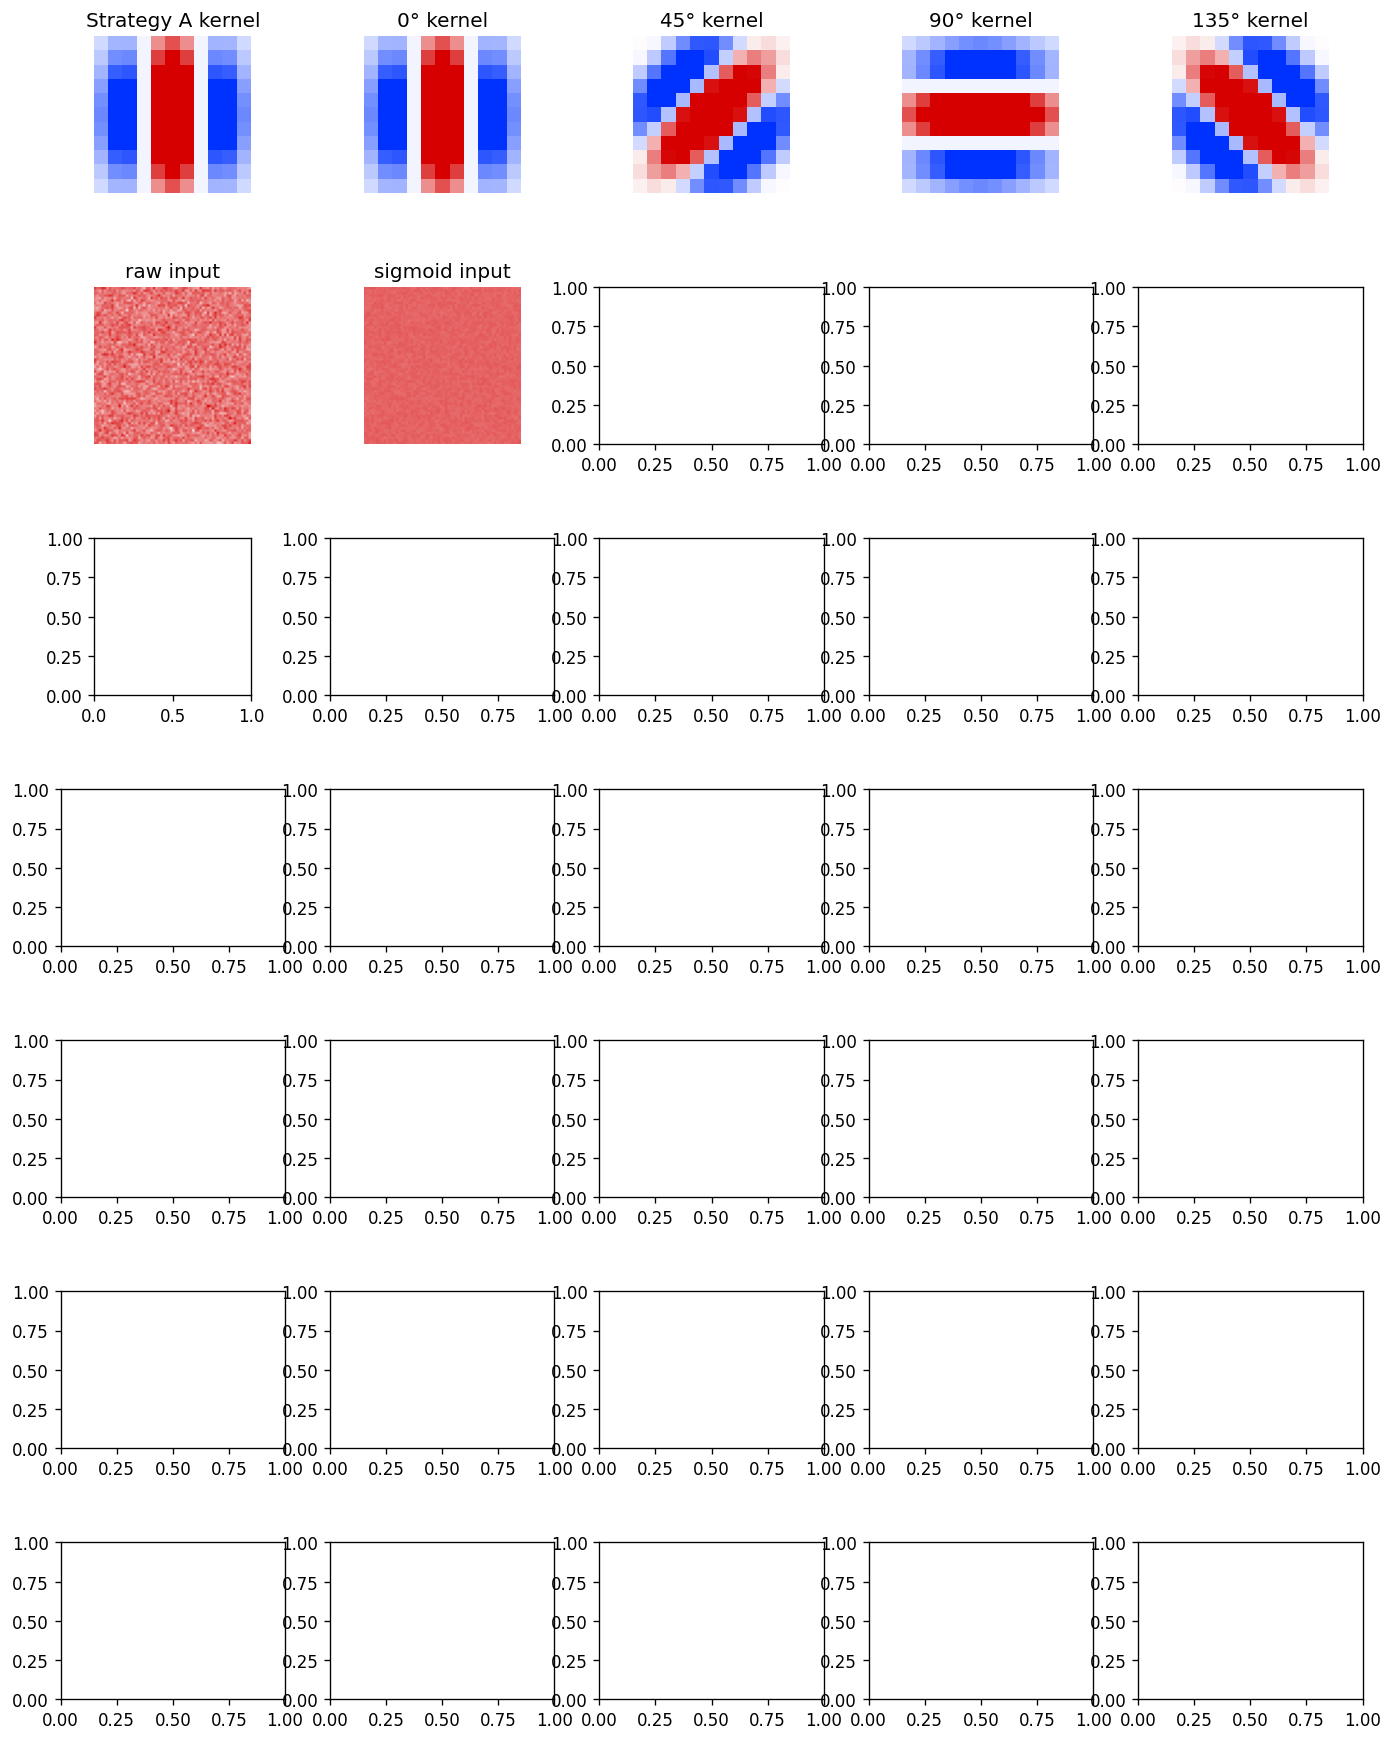

In [23]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""
Two biologically inspired ways to obtain the sliding‑window effect of CNN
filters with E/I synapses.

Strategy A:  One neuron with many dendritic *branches* that look at
             different patches of the same image (weight sharing).

Strategy B:  A first layer of Gabor neurons produces four feature maps.
             A second‑layer neuron receives those maps via four dendrites
             (one per upstream cell).

Author:  <your‑name>
Date  :  2025‑07‑10
"""

# ------------------------- #
#      Dependencies         #
# ------------------------- #
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
plt.rcParams["figure.dpi"] = 120

# handy diverging map for ± valued data
rwb_cmap = LinearSegmentedColormap.from_list(
    "rwb", ["#0032FF", "#FFFFFF", "#D60000"], N=256
)

# ------------------------- #
#    Helper: Gabor kernel   #
# ------------------------- #
def create_gabor_filter(size, wavelength, orientation,
                        phase, sigma, aspect_ratio=1.0):
    x = np.arange(size) - size // 2
    y = np.arange(size) - size // 2
    X, Y = np.meshgrid(x, y)
    θ = np.deg2rad(orientation)
    Xr =  X * np.cos(θ) + Y * np.sin(θ)
    Yr = -X * np.sin(θ) + Y * np.cos(θ)
    gauss = np.exp(-(Xr**2 + (Yr/aspect_ratio)**2)/(2*sigma**2))
    sinus = np.cos(2*np.pi*Xr/wavelength + phase)
    gabor = gauss * sinus
    gabor = (gabor - gabor.mean()) / (gabor.std() + 1e-9)  # z‑score
    return gabor.astype(np.float32)

def solve_linear_weights(target):
    E = np.maximum(target, 0)
    I = np.maximum(-target, 0)
    if E.max() > 0: E /= E.max()
    if I.max() > 0: I /= I.max()
    return E, I

def solve_shunting_weights(target):
    t = (target - target.min()) / (target.max() - target.min() + 1e-9)
    E = np.full_like(target, 0.1)
    I = np.full_like(target, 0.1)
    hi = t > .5
    E[hi] = 2.0 * t[hi];     I[hi] = 0.10
    lo = ~hi
    I[lo] = 2.0 * (1 - t[lo]); E[lo] = 0.10
    return E, I

# ------------------------- #
#       Modules (A)         #
# ------------------------- #
class SlidingDendriteNeuron(nn.Module):
    """
    Strategy A
    A *single* neuron whose many dendritic branches correspond to the
    sliding windows of a convolution.  Internally implemented with two
    weight‑shared conv kernels (E and I).
    By design, every branch uses *identical weights*; weight sharing is
    therefore achieved without creating multiple somata.
    """
    def __init__(self, kernel_size, neuron_type="linear"):
        super().__init__()
        self.neuron_type = neuron_type
        self.k = kernel_size
        # raw log‑weights so they stay positive
        self.wE_raw = nn.Parameter(torch.log(
            torch.ones(1, 1, kernel_size, kernel_size)*1e-3))
        self.wI_raw = nn.Parameter(torch.log(
            torch.ones(1, 1, kernel_size, kernel_size)*1e-3))

    def forward(self, x, aggregate=True):
        """
        x: (B,1,H,W)
        aggregate=True  -> scalar soma potential  (B,1)
        aggregate=False -> full spatial map       (B,1,H,W)
        """
        wE = torch.exp(self.wE_raw)
        wI = torch.exp(self.wI_raw)
        E = F.conv2d(x, wE, padding=self.k//2)
        I = F.conv2d(x, wI, padding=self.k//2)

        if self.neuron_type == "linear":
            V = E - I
        elif self.neuron_type == "shunting":
            V = E / (E + I + 1.)
        else:
            raise ValueError(self.neuron_type)

        if aggregate:
            # soma sums over dendrites (branches)
            V = V.mean(dim=(-2, -1))   # (B,1)
        return V


# ------------------------- #
#       Modules (B)         #
# ------------------------- #
class DendriticConv2d(nn.Module):
    """
    First‑layer Gabor neuron (like earlier answers).
    Weight sharing = scanning each receptive field over the image.
    """
    def __init__(self, kernel_size, neuron_type="linear"):
        super().__init__()
        self.neuron_type = neuron_type
        k = kernel_size
        self.wE_raw = nn.Parameter(torch.log(torch.ones(1,1,k,k)*1e-3))
        self.wI_raw = nn.Parameter(torch.log(torch.ones(1,1,k,k)*1e-3))

    def forward(self, x):
        wE = torch.exp(self.wE_raw); wI = torch.exp(self.wI_raw)
        E = F.conv2d(x, wE, padding=wE.shape[-1]//2)
        I = F.conv2d(x, wI, padding=wI.shape[-1]//2)
        if self.neuron_type == "linear":
            V = E - I
        else:
            V = E / (E + I + 1.)
        return V  # (B,1,H,W)

class SomaIntegrator(nn.Module):
    """
    Receives *feature maps* from several upstream neurons.
    Each map is considered one dendrite (weight = 1 by default, but
    could be learned/hand‑set).  For simplicity we only do linear sum.
    """
    def __init__(self, n_dendrites, neuron_type="linear"):
        super().__init__()
        self.neuron_type = neuron_type
        # excitatory & inhibitory *scalars* (one per upstream map)
        self.wE_raw = nn.Parameter(torch.log(torch.ones(1,n_dendrites,1,1)*1e-3))
        self.wI_raw = nn.Parameter(torch.log(torch.ones(1,n_dendrites,1,1)*1e-3))

    def forward(self, xs):  # xs list of feature maps, each (B,1,H,W)
        x = torch.cat(xs, dim=1)       # (B,N,H,W)
        wE = torch.exp(self.wE_raw); wI = torch.exp(self.wI_raw)
        E = (x * wE).sum(dim=1, keepdim=True)   # (B,1,H,W)
        I = (x * wI).sum(dim=1, keepdim=True)
        if self.neuron_type == "linear":
            V = E - I
        else:
            V = E / (E + I + 1.)
        return V

class TwoLayerCascade(nn.Module):
    """
    Strategy B: four orientation‑selective Gabor neurons feeding one soma.
    """
    def __init__(self, kernel_size, orientations, first_type="linear",
                 second_type="linear"):
        super().__init__()
        self.first = nn.ModuleList(
            [DendriticConv2d(kernel_size, neuron_type=first_type)
             for _ in orientations])
        self.soma  = SomaIntegrator(len(orientations), neuron_type=second_type)

    def forward(self, x):
        maps = [cell(x) for cell in self.first]   # list of (B,1,H,W)
        out  = self.soma(maps)                   # (B,1,H,W)
        return maps, out


# ------------------------- #
#      Build the models     #
# ------------------------- #
kernel = 11
orientations = [0, 45, 90, 135]

# helper to initialise first‑layer weights
def set_gabor_weights(layer, orientation, kind="linear"):
    g = create_gabor_filter(kernel, 8, orientation, 0, 3)
    if kind == "linear":
        E, I = solve_linear_weights(g)
    else:
        E, I = solve_shunting_weights(g)
    with torch.no_grad():
        layer.wE_raw[0,0] = torch.log(torch.tensor(E)+1e-6)
        layer.wI_raw[0,0] = torch.log(torch.tensor(I)+1e-6)
    return g, E, I

# ---- Strategy A (one neuron, many branches) ----
slide_neuron_L  = SlidingDendriteNeuron(kernel, neuron_type="linear")
slide_neuron_S  = SlidingDendriteNeuron(kernel, neuron_type="shunting")
gabor_A, E_A, I_A = set_gabor_weights(slide_neuron_L, 0, "linear")  # same weights

# ---- Strategy B (cascade) ----
cascade_L = TwoLayerCascade(kernel, orientations,
                            first_type="linear", second_type="linear")
cascade_S = TwoLayerCascade(kernel, orientations,
                            first_type="linear", second_type="shunting")

# set first layer weights
gabors_B = []
for ori, cell in zip(orientations, cascade_L.first):
    g, E_, I_ = set_gabor_weights(cell, ori, "linear")
    gabors_B.append(g)
    # cascade_S shares the same first‑layer cells
    set_gabor_weights(cascade_S.first[orientations.index(ori)],
                      ori, "linear")

# ------------------------- #
#     Prepare an example    #
# ------------------------- #
np.random.seed(0)
torch.manual_seed(0)
# whitened random patch  (approximate)
img = torch.tensor(np.random.randn(1, 1, 64, 64), dtype=torch.float32)

# Run Strategy A
raw_in   = img.clone()
sig_in   = torch.sigmoid(raw_in)
with torch.no_grad():
    V_A_lin = slide_neuron_L(sig_in, aggregate=False)[0]  # map view
    V_A_shu = slide_neuron_S(sig_in, aggregate=False)[0]

# Run Strategy B
with torch.no_grad():
    maps_L, V_B_lin = cascade_L(sig_in)
    _,      V_B_shu = cascade_S(sig_in)

# ------------------------- #
#         Plotting          #
# ------------------------- #
def shared_limits(*arrays):
    arr = np.concatenate([a.reshape(-1) for a in arrays])
    return float(arr.min()), float(arr.max())

common_min, common_max = shared_limits(
    raw_in.numpy(), sig_in.numpy(),
    V_A_lin.numpy(), V_A_shu.numpy(),
    V_B_lin.numpy(), V_B_shu.numpy()
)

fig, axes = plt.subplots(7, 5, figsize=(14, 18),
                         gridspec_kw={'hspace': .6})

# Row 0 – first‑layer Gabors (strategy B) + one for strategy A
axes[0,0].imshow(gabor_A, cmap=rwb_cmap, vmin=-1, vmax=1)
axes[0,0].axis('off'); axes[0,0].set_title("Strategy A kernel")
for i, g in enumerate(gabors_B):
    ax = axes[0, i+1]
    ax.imshow(g, cmap=rwb_cmap, vmin=-1, vmax=1)
    ax.axis('off'); ax.set_title(f"{orientations[i]}° kernel")

# Row 1 – raw & sigmoid input
axes[1,0].imshow(raw_in[0,0], cmap=rwb_cmap,
                 vmin=common_min, vmax=common_max)
axes[1,0].axis('off'); axes[1,0].set_title("raw input")
axes[1,1].imshow(sig_in[0,0], cmap=rwb_cmap,
                 vmin=common_min, vmax=common_max)
axes[1,1].axis('off'); axes[1,1].set_title("sigmoid input")

# Row 2‑3 – Strategy A outputs
axes[2,0].imshow(V_A_lin, cmap=rwb_cmap,
                 vmin=common_min, vmax=common_max)
axes[2,0].axis('off'); axes[2,0].set_title("A linear output")
axes[3,0].imshow(V_A_shu, cmap=rwb_cmap,
                 vmin=common_min, vmax=common_max)
axes[3,0].axis('off'); axes[3,0].set_title("A shunt output")

# Row 4‑5 – Strategy B first‑layer maps (linear)
for i, m in enumerate(maps_L):
    ax = axes[4, i+1]
    ax.imshow(m[0,0], cmap=rwb_cmap,
              vmin=common_min, vmax=common_max)
    ax.axis('off'); ax.set_title(f"1st layer {orientations[i]}°")

# Row 6 – Strategy B soma outputs
axes[5,0].imshow(V_B_lin[0,0], cmap=rwb_cmap,
                 vmin=common_min, vmax=common_max)
axes[5,0].axis('off'); axes[5,0].set_title("B linear soma")
axes[6,0].imshow(V_B_shu[0,0], cmap=rwb_cmap,
                 vmin=common_min, vmax=common_max)
axes[6,0].axis('off'); axes[6,0].set_title("B shunt soma")

plt.suptitle("Strategy A: many dendrites / Strategy B: two‑layer cascade",
             fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ------------------------- #
#       Quick stats         #
# ------------------------- #
def corr(a, b):
    a = (a - a.mean()) / (a.std() + 1e-9)
    b = (b - b.mean()) / (b.std() + 1e-9)
    return float(np.corrcoef(a.reshape(-1), b.reshape(-1))[0,1])

print("Correlation between the two strategies on this image:")
print(f"  linear  : r = {corr(V_A_lin.numpy(), V_B_lin.numpy()):+.3f}")
print(f"  shunting: r = {corr(V_A_shu.numpy(), V_B_shu.numpy()):+.3f}")

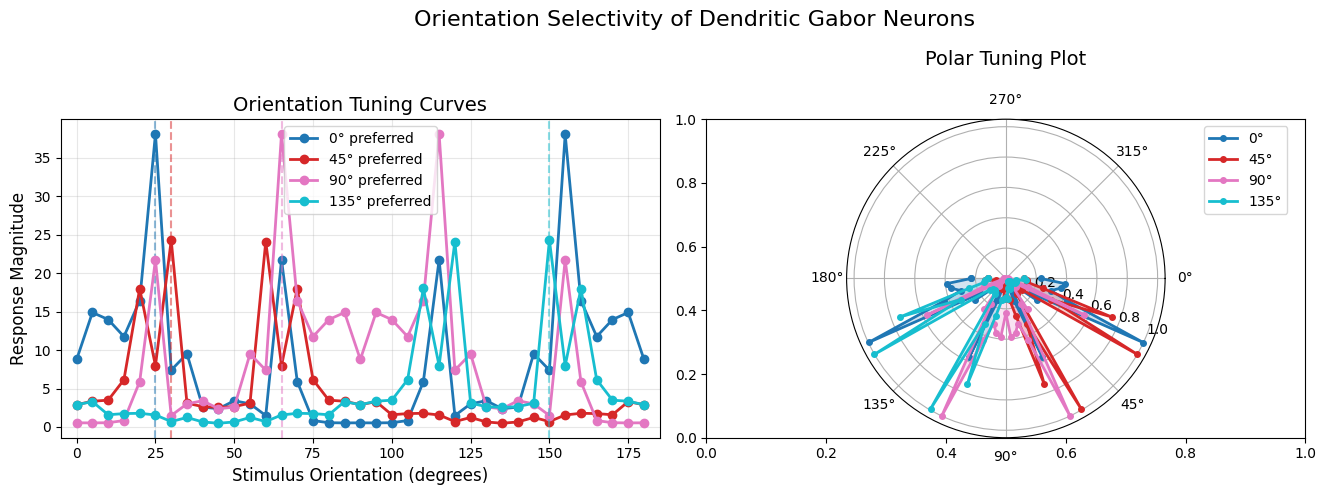

Orientation Selectivity Index (OSI):
  Neuron 0°: OSI = 0.972
  Neuron 45°: OSI = 0.961
  Neuron 90°: OSI = 0.972
  Neuron 135°: OSI = 0.961


In [ ]:
def create_oriented_grating(size, orientation, wavelength, phase=0):
    """Create an oriented sinusoidal grating."""
    x = np.arange(size) - size // 2
    y = np.arange(size) - size // 2
    X, Y = np.meshgrid(x, y)
    
    # Rotate coordinates
    theta = np.deg2rad(orientation)
    X_rot = X * np.cos(theta) + Y * np.sin(theta)
    
    # Create grating
    grating = np.sin(2 * np.pi * X_rot / wavelength + phase)
    
    # Apply circular aperture
    radius = size // 2 - 5
    mask = (X**2 + Y**2) <= radius**2
    grating = grating * mask
    
    return grating

def test_orientation_tuning(neurons, test_orientations):
    """Test orientation tuning of neurons."""
    responses = np.zeros((len(neurons), len(test_orientations)))
    
    for i, neuron in enumerate(neurons):
        for j, test_ori in enumerate(test_orientations):
            # Create test grating
            grating = create_oriented_grating(64, test_ori, 8)
            grating_tensor = torch.tensor(grating, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
            
            # Get response
            with torch.no_grad():
                response = neuron(grating_tensor)
                responses[i, j] = response.abs().mean().item()
    
    return responses

# Test orientation tuning
test_angles = np.linspace(0, 180, 37)  # 5-degree steps
tuning_curves = test_orientation_tuning(gabor_neurons, test_angles)

# Plot tuning curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Individual tuning curves
colors = plt.cm.tab10(np.linspace(0, 1, len(orientations)))
for i, (ori, curve) in enumerate(zip(orientations, tuning_curves)):
    ax1.plot(test_angles, curve, 'o-', color=colors[i], 
             label=f'{ori}° preferred', linewidth=2, markersize=6)
    
    # Mark preferred orientation
    max_idx = np.argmax(curve)
    ax1.axvline(test_angles[max_idx], color=colors[i], linestyle='--', alpha=0.5)

ax1.set_xlabel('Stimulus Orientation (degrees)', fontsize=12)
ax1.set_ylabel('Response Magnitude', fontsize=12)
ax1.set_title('Orientation Tuning Curves', fontsize=14)
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_xlim(-5, 185)

# Polar plot
ax2 = plt.subplot(122, projection='polar')
theta = np.deg2rad(np.concatenate([test_angles, [180]]))  # Complete circle

for i, (ori, curve) in enumerate(zip(orientations, tuning_curves)):
    # Normalize and complete circle
    curve_norm = curve / curve.max()
    curve_complete = np.concatenate([curve_norm, [curve_norm[0]]])
    
    ax2.plot(theta, curve_complete, 'o-', color=colors[i], 
             label=f'{ori}°', linewidth=2, markersize=4)
    ax2.fill(theta, curve_complete, color=colors[i], alpha=0.2)

ax2.set_title('Polar Tuning Plot', fontsize=14, pad=20)
ax2.set_theta_zero_location('E')
ax2.set_theta_direction(-1)
ax2.legend(loc='upper left', bbox_to_anchor=(1.1, 1))

plt.suptitle('Orientation Selectivity of Dendritic Gabor Neurons', fontsize=16)
plt.tight_layout()
plt.show()

# Calculate orientation selectivity index (OSI)
print("Orientation Selectivity Index (OSI):")
for i, ori in enumerate(orientations):
    pref_resp = tuning_curves[i].max()
    orth_idx = np.argmin(np.abs(test_angles - (ori + 90) % 180))
    orth_resp = tuning_curves[i, orth_idx]
    osi = (pref_resp - orth_resp) / (pref_resp + orth_resp)
    print(f"  Neuron {ori}°: OSI = {osi:.3f}")


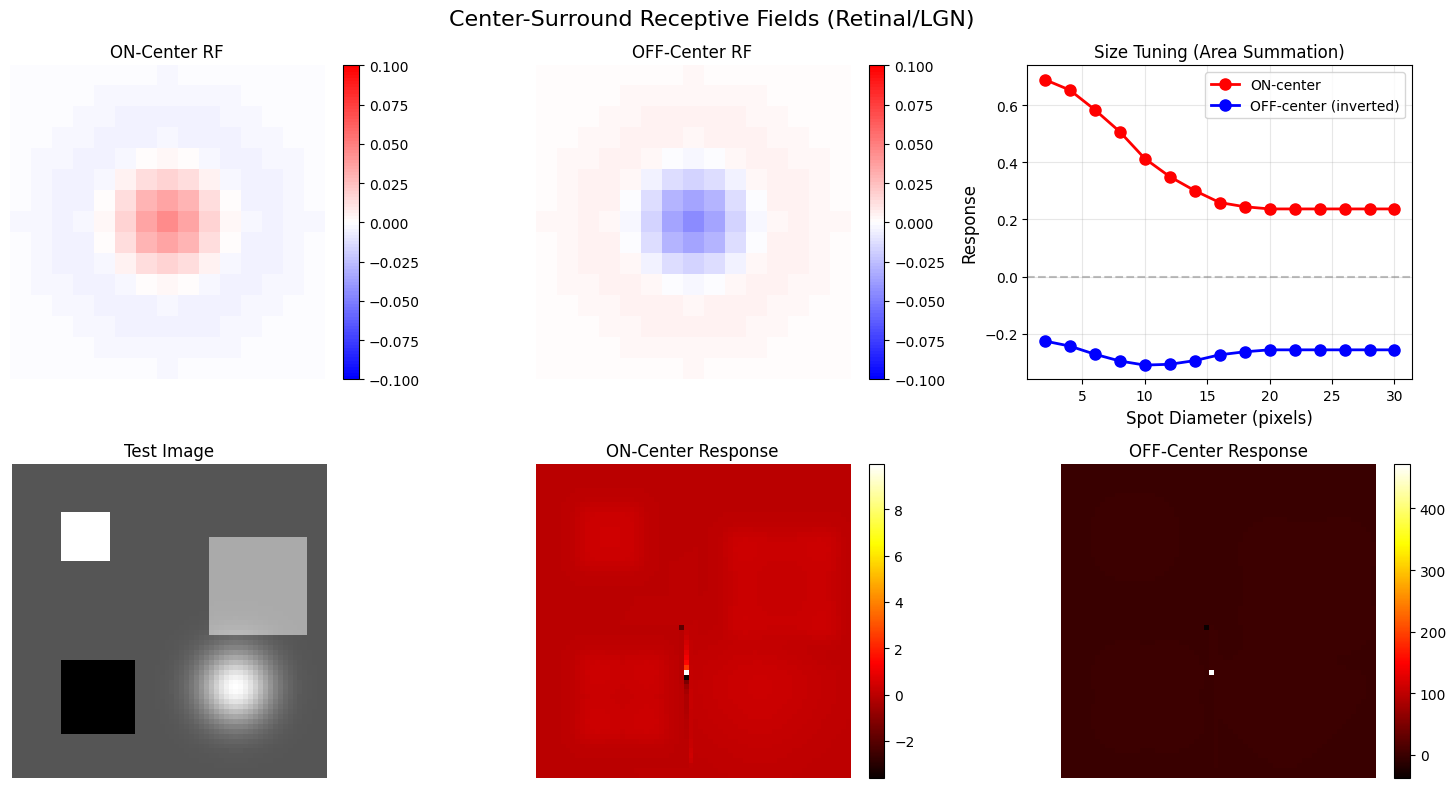

In [ ]:
def create_center_surround_neuron(kernel_size=15, center_size=5, surround_size=11, 
                                  cell_type='on-center'):
    """Create a center-surround receptive field neuron."""
    # Create Gaussian kernels
    x = np.arange(kernel_size) - kernel_size // 2
    y = np.arange(kernel_size) - kernel_size // 2
    X, Y = np.meshgrid(x, y)
    
    # Center Gaussian
    center = np.exp(-(X**2 + Y**2) / (2 * (center_size/3)**2))
    center = center / center.sum()
    
    # Surround Gaussian
    surround = np.exp(-(X**2 + Y**2) / (2 * (surround_size/3)**2))
    surround = surround / surround.sum()
    
    # Create layer
    layer = DendriteConv2d(
        in_channels=1,
        out_channels=1,
        kernel_size=kernel_size,
        padding=kernel_size//2,
        bias=False
    )
    
    # Set weights based on cell type
    with torch.no_grad():
        if cell_type == 'on-center':
            # ON-center: center excitatory, surround inhibitory
            E_weights = center * 10
            I_weights = surround * 8 + 0.1
        else:  # off-center
            # OFF-center: center inhibitory, surround excitatory
            E_weights = surround * 10
            I_weights = center * 8 + 0.1
        
        layer.weight_E_raw.data[0, 0] = torch.log(torch.tensor(E_weights).float() + 1e-6)
        layer.weight_I_raw.data[0, 0] = torch.log(torch.tensor(I_weights).float() + 1e-6)
    
    return layer, center - surround

# Create ON and OFF center neurons
on_center_neuron, on_rf = create_center_surround_neuron(cell_type='on-center')
off_center_neuron, off_rf = create_center_surround_neuron(cell_type='off-center')

# Test with spots of different sizes
def test_size_tuning(neuron, spot_sizes, image_size=64):
    """Test response to spots of different sizes."""
    responses = []
    
    for size in spot_sizes:
        # Create centered spot
        image = np.zeros((image_size, image_size))
        center = image_size // 2
        y, x = np.ogrid[:image_size, :image_size]
        mask = (x - center)**2 + (y - center)**2 <= (size/2)**2
        image[mask] = 1.0
        
        # Get response
        img_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
        with torch.no_grad():
            response = neuron(img_tensor)
            responses.append(response[0, 0, center, center].item())
    
    return np.array(responses)

# Test size tuning
spot_sizes = np.linspace(2, 30, 15)
on_responses = test_size_tuning(on_center_neuron, spot_sizes)
off_responses = test_size_tuning(off_center_neuron, spot_sizes)

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Receptive fields
im1 = axes[0, 0].imshow(on_rf, cmap=rwb_cmap, vmin=-0.1, vmax=0.1)
axes[0, 0].set_title('ON-Center RF', fontsize=12)
axes[0, 0].axis('off')
plt.colorbar(im1, ax=axes[0, 0], fraction=0.046)

im2 = axes[0, 1].imshow(-off_rf, cmap=rwb_cmap, vmin=-0.1, vmax=0.1)
axes[0, 1].set_title('OFF-Center RF', fontsize=12)
axes[0, 1].axis('off')
plt.colorbar(im2, ax=axes[0, 1], fraction=0.046)

# Size tuning curves
axes[0, 2].plot(spot_sizes, on_responses, 'ro-', label='ON-center', linewidth=2, markersize=8)
axes[0, 2].plot(spot_sizes, -off_responses, 'bo-', label='OFF-center (inverted)', linewidth=2, markersize=8)
axes[0, 2].axhline(0, color='gray', linestyle='--', alpha=0.5)
axes[0, 2].set_xlabel('Spot Diameter (pixels)', fontsize=12)
axes[0, 2].set_ylabel('Response', fontsize=12)
axes[0, 2].set_title('Size Tuning (Area Summation)', fontsize=12)
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# Test with natural-like stimuli
test_image = np.zeros((64, 64))
# Add various features
test_image[10:20, 10:20] = 1  # Small bright square
test_image[40:55, 10:25] = -0.5  # Dark rectangle
test_image[15:35, 40:60] = 0.5  # Medium rectangle
# Add Gaussian blob
x, y = np.ogrid[:64, :64]
gaussian_blob = np.exp(-((x-45)**2 + (y-45)**2) / (2 * 5**2))
test_image += gaussian_blob

# Process through neurons
test_tensor = torch.tensor(test_image, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
with torch.no_grad():
    on_response = on_center_neuron(test_tensor)
    off_response = off_center_neuron(test_tensor)

# Display results
axes[1, 0].imshow(test_image, cmap='gray')
axes[1, 0].set_title('Test Image', fontsize=12)
axes[1, 0].axis('off')

im3 = axes[1, 1].imshow(on_response[0, 0].numpy(), cmap='hot')
axes[1, 1].set_title('ON-Center Response', fontsize=12)
axes[1, 1].axis('off')
plt.colorbar(im3, ax=axes[1, 1], fraction=0.046)

im4 = axes[1, 2].imshow(off_response[0, 0].numpy(), cmap='hot')
axes[1, 2].set_title('OFF-Center Response', fontsize=12)
axes[1, 2].axis('off')
plt.colorbar(im4, ax=axes[1, 2], fraction=0.046)

plt.suptitle('Center-Surround Receptive Fields (Retinal/LGN)', fontsize=16)
plt.tight_layout()
plt.show()


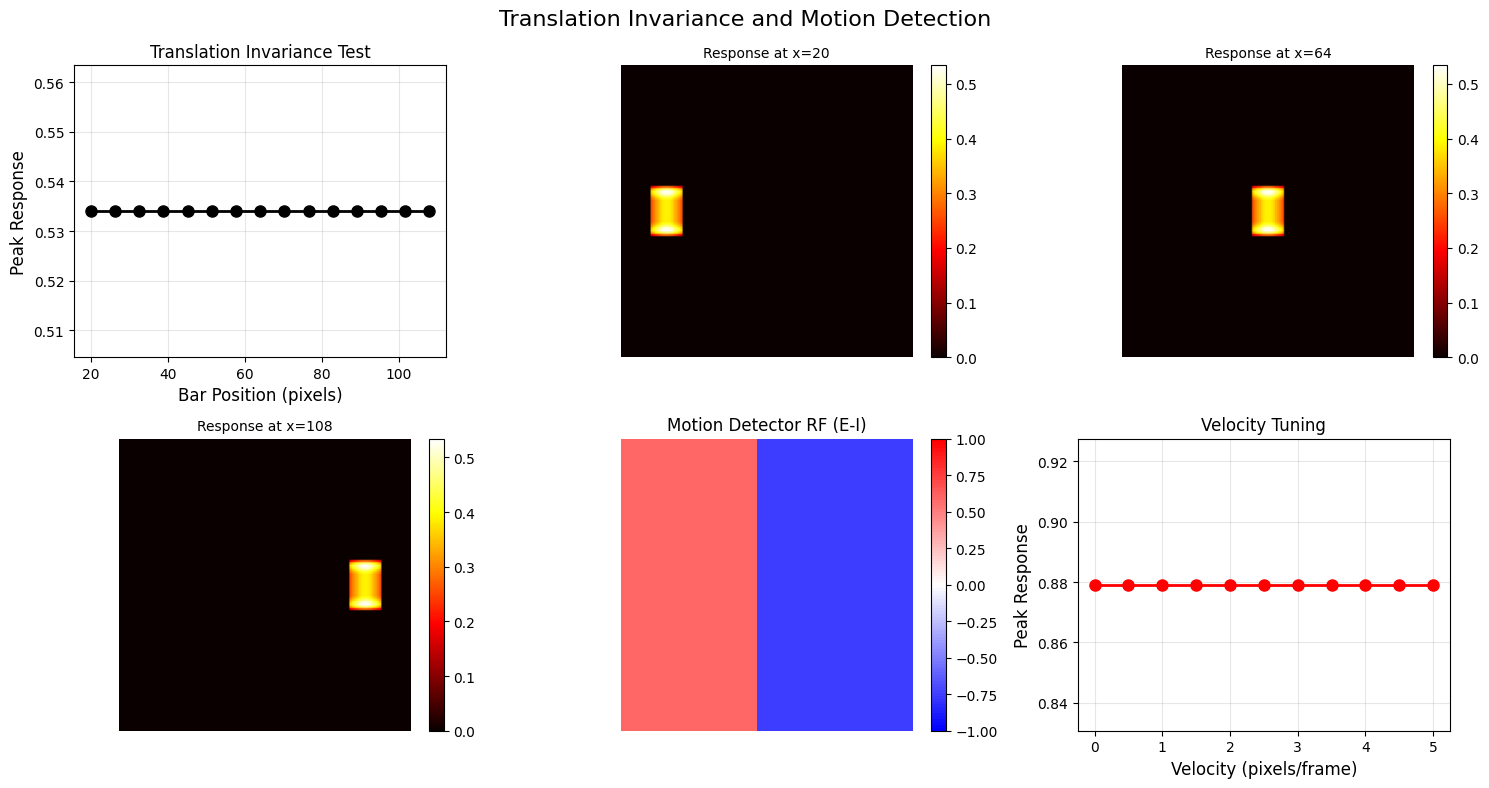

Translation Invariance:
  Response variance: 0.0000
  Coefficient of variation: 0.000


In [ ]:
def test_translation_invariance(neuron, image_size=128, bar_length=20, bar_width=4):
    """Test translation invariance by moving a bar across the visual field."""
    # Create oriented bar
    bar = np.zeros((bar_length, bar_width))
    bar[:, :] = 1.0
    
    # Test positions
    positions = np.linspace(20, image_size-20, 15)
    responses = []
    response_maps = []
    
    for pos in positions:
        # Create image with translated bar
        image = np.zeros((image_size, image_size))
        x_start = int(pos - bar_width//2)
        y_start = image_size//2 - bar_length//2
        
        # Place bar
        image[y_start:y_start+bar_length, x_start:x_start+bar_width] = 1.0
        
        # Get response
        img_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
        with torch.no_grad():
            response = neuron(img_tensor)
            responses.append(response.max().item())
            response_maps.append(response[0, 0].numpy())
    
    return positions, responses, response_maps

# Test translation invariance for vertical Gabor
positions, responses, response_maps = test_translation_invariance(gabor_neurons[2])  # 90° neuron

# Create motion-sensitive neuron (Reichardt detector inspired)
def create_motion_detector(direction='rightward', delay_frames=2):
    """Create a motion-sensitive neuron using spatiotemporal E/I patterns."""
    kernel_size = 15
    
    # Create spatiotemporal kernel
    if direction == 'rightward':
        # Excitation on the left (earlier), inhibition on the right (later)
        E_weights = np.zeros((kernel_size, kernel_size))
        I_weights = np.zeros((kernel_size, kernel_size))
        
        # E: Left side responds to current frame
        E_weights[:, :kernel_size//2] = gaussian_filter(
            np.ones((kernel_size, kernel_size//2)), sigma=2)
        
        # I: Right side responds to delayed frame (motion opponent)
        I_weights[:, kernel_size//2:] = gaussian_filter(
            np.ones((kernel_size, kernel_size//2+1)), sigma=2)
        
    # Normalize and add baseline
    E_weights = E_weights / (E_weights.max() + 1e-6)
    I_weights = I_weights / (I_weights.max() + 1e-6) + 0.1
    
    # Create layer
    layer = DendriteConv2d(
        in_channels=1,
        out_channels=1,
        kernel_size=kernel_size,
        padding=kernel_size//2,
        bias=False
    )
    
    with torch.no_grad():
        layer.weight_E_raw.data[0, 0] = torch.log(torch.tensor(E_weights).float() + 1e-6)
        layer.weight_I_raw.data[0, 0] = torch.log(torch.tensor(I_weights).float() + 1e-6)
    
    return layer

# Create motion detectors for different directions
motion_detector = create_motion_detector('rightward')

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Translation invariance results
ax1 = axes[0, 0]
ax1.plot(positions, responses, 'ko-', linewidth=2, markersize=8)
ax1.set_xlabel('Bar Position (pixels)', fontsize=12)
ax1.set_ylabel('Peak Response', fontsize=12)
ax1.set_title('Translation Invariance Test', fontsize=12)
ax1.grid(True, alpha=0.3)

# Show some response maps
for i, idx in enumerate([0, len(positions)//2, -1]):
    ax = axes[0, i+1] if i < 2 else axes[1, 0]
    im = ax.imshow(response_maps[idx], cmap='hot')
    ax.set_title(f'Response at x={positions[idx]:.0f}', fontsize=10)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

# Motion detector receptive field
with torch.no_grad():
    E = motion_detector.weight_E[0, 0].numpy()
    I = motion_detector.weight_I[0, 0].numpy()
    
ax = axes[1, 1]
im = ax.imshow(E - I, cmap=rwb_cmap, vmin=-1, vmax=1)
ax.set_title('Motion Detector RF (E-I)', fontsize=12)
ax.axis('off')
plt.colorbar(im, ax=ax, fraction=0.046)

# Test motion sensitivity
def test_motion_response(detector, velocities):
    """Test response to moving bars at different velocities."""
    responses = []
    image_size = 64
    bar_width = 4
    
    for velocity in velocities:
        # Simulate motion sequence
        frames = []
        n_frames = 10
        
        for t in range(n_frames):
            image = np.zeros((image_size, image_size))
            x_pos = int(10 + velocity * t)
            
            if 0 <= x_pos < image_size - bar_width:
                image[:, x_pos:x_pos+bar_width] = 1.0
            
            frames.append(image)
        
        # Process sequence (simplified - just max response)
        frame_responses = []
        for frame in frames:
            img_tensor = torch.tensor(frame, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
            with torch.no_grad():
                resp = detector(img_tensor)
                frame_responses.append(resp.max().item())
        
        responses.append(np.max(frame_responses))
    
    return responses

# Test different velocities
velocities = np.linspace(0, 5, 11)
motion_responses = test_motion_response(motion_detector, velocities)

ax = axes[1, 2]
ax.plot(velocities, motion_responses, 'ro-', linewidth=2, markersize=8)
ax.set_xlabel('Velocity (pixels/frame)', fontsize=12)
ax.set_ylabel('Peak Response', fontsize=12)
ax.set_title('Velocity Tuning', fontsize=12)
ax.grid(True, alpha=0.3)

plt.suptitle('Translation Invariance and Motion Detection', fontsize=16)
plt.tight_layout()
plt.show()

print("Translation Invariance:")
print(f"  Response variance: {np.var(responses):.4f}")
print(f"  Coefficient of variation: {np.std(responses)/np.mean(responses):.3f}")


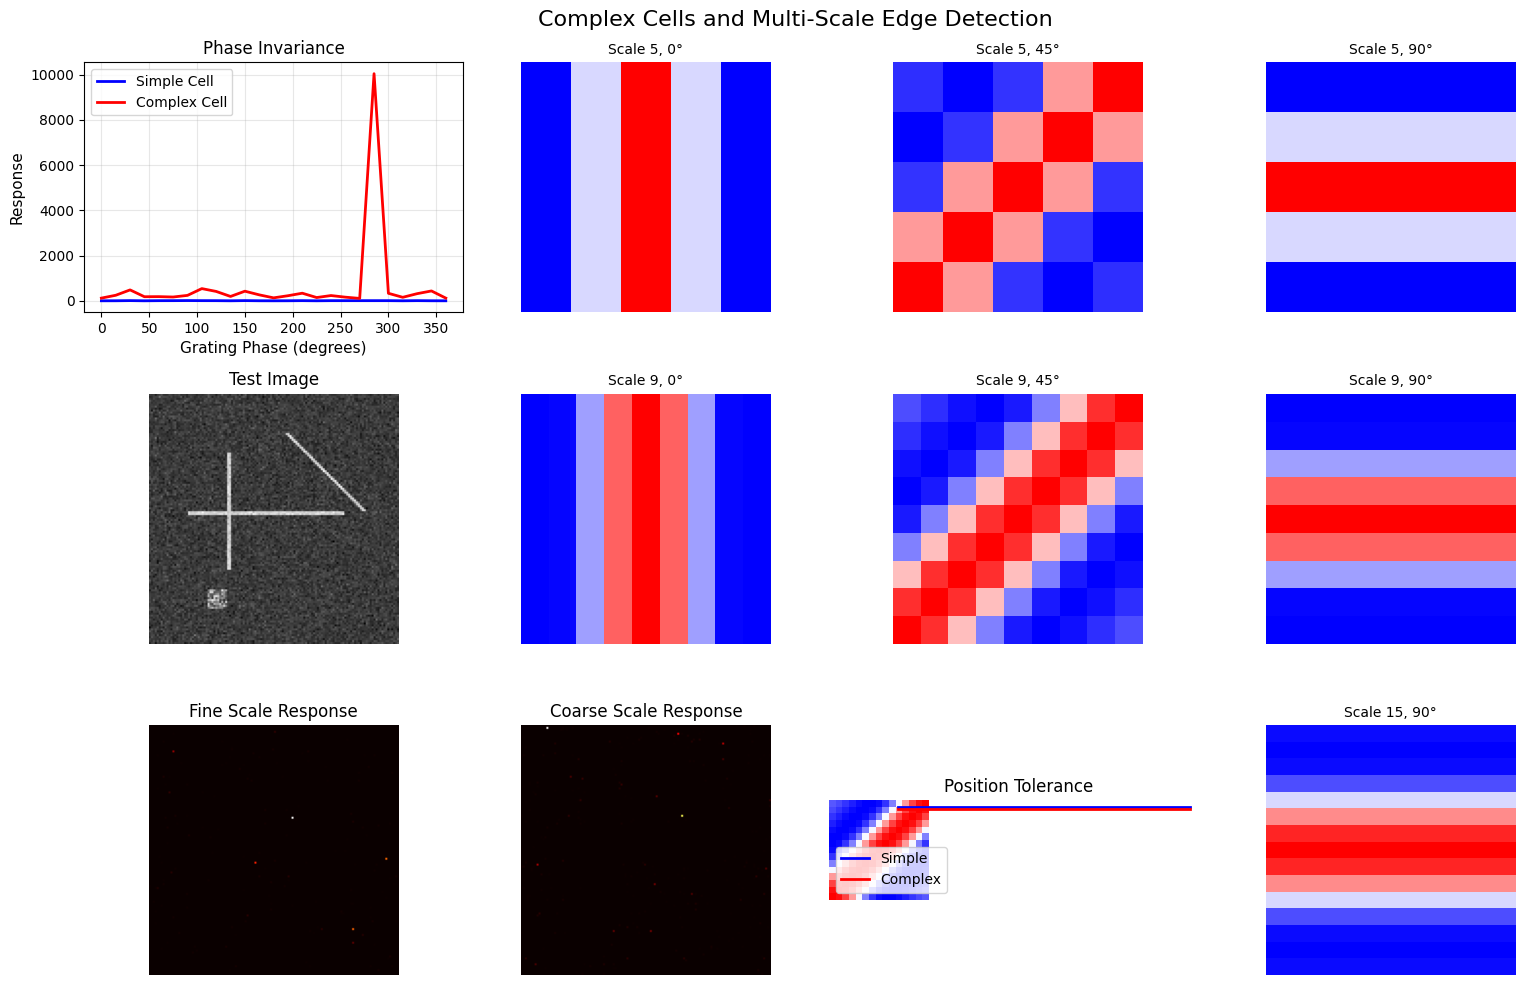

Invariance Metrics:
  Simple cell phase variance: 9.8434
  Complex cell phase variance: 3686549.3836
  Variance reduction: -37451868.3%


In [ ]:
class ComplexCell(nn.Module):
    """Complex cell that pools multiple simple cells with phase/position variance."""
    
    def __init__(self, orientation, n_phases=4, n_positions=3):
        super().__init__()
        self.orientation = orientation
        self.n_phases = n_phases
        self.n_positions = n_positions
        
        # Create simple cells with different phases
        self.simple_cells = nn.ModuleList()
        
        phases = np.linspace(0, np.pi, n_phases)
        positions = np.linspace(-2, 2, n_positions)
        
        for phase in phases:
            for pos in positions:
                # Create Gabor with specific phase and position
                gabor = create_gabor_filter(11, 8, orientation, phase, 3)
                
                # Shift position
                gabor_shifted = np.roll(gabor, int(pos), axis=1)
                
                # Create dendritic neuron
                layer = DendriteConv2d(
                    in_channels=1,
                    out_channels=1,
                    kernel_size=11,
                    padding=5,
                    bias=False
                )
                
                # Set weights
                E_weights = np.maximum(gabor_shifted, 0) + 0.01
                I_weights = np.maximum(-gabor_shifted, 0) + 0.1
                
                with torch.no_grad():
                    layer.weight_E_raw.data[0, 0] = torch.log(torch.tensor(E_weights).float() + 1e-6)
                    layer.weight_I_raw.data[0, 0] = torch.log(torch.tensor(I_weights).float() + 1e-6)
                
                self.simple_cells.append(layer)
        
        # Energy model pooling (squared responses)
        self.pool = nn.MaxPool2d(3, stride=1, padding=1)
    
    def forward(self, x):
        # Get responses from all simple cells
        responses = []
        for cell in self.simple_cells:
            resp = cell(x)
            # Use absolute value instead of squaring to avoid explosion
            responses.append(torch.abs(resp))
        
        # Pool across cells
        stacked = torch.stack(responses, dim=1)
        pooled = torch.max(stacked, dim=1)[0]  # Max pooling across phases/positions
        
        # Spatial pooling
        output = self.pool(pooled)
        
        return output

# Create complex cells
complex_cell_0 = ComplexCell(orientation=0)
complex_cell_90 = ComplexCell(orientation=90)

# Test phase invariance
def test_phase_invariance(simple_cell, complex_cell, phases):
    """Test response to gratings with different phases."""
    simple_responses = []
    complex_responses = []
    
    for phase in phases:
        # Create grating with specific phase
        grating = create_oriented_grating(64, complex_cell.orientation, 8, phase)
        grating_tensor = torch.tensor(grating, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
        
        # Simple cell response
        with torch.no_grad():
            simple_resp = simple_cell(grating_tensor)
            simple_responses.append(simple_resp.abs().mean().item())
            
            # Complex cell response
            complex_resp = complex_cell(grating_tensor)
            complex_responses.append(complex_resp.abs().mean().item())
    
    return simple_responses, complex_responses

# Test
phases = np.linspace(0, 2*np.pi, 25)
simple_resp, complex_resp = test_phase_invariance(gabor_neurons[0], complex_cell_0, phases)

# Create edge detector hierarchy
def create_edge_detector_bank():
    """Create a bank of edge detectors at multiple scales."""
    scales = [5, 9, 15]
    orientations = [0, 45, 90, 135]
    
    detectors = {}
    
    for scale in scales:
        detectors[scale] = []
        for ori in orientations:
            # Create DoG (Difference of Gaussians) edge detector
            layer = DendriteConv2d(
                in_channels=1,
                out_channels=1,
                kernel_size=scale,
                padding=scale//2,
                bias=False
            )
            
            # Create DoG kernel
            x = np.arange(scale) - scale // 2
            y = np.arange(scale) - scale // 2
            X, Y = np.meshgrid(x, y)
            
            # Rotate for orientation
            theta = np.deg2rad(ori)
            X_rot = X * np.cos(theta) + Y * np.sin(theta)
            Y_rot = -X * np.sin(theta) + Y * np.cos(theta)
            
            # DoG along one direction
            g1 = np.exp(-(X_rot**2) / (2 * (scale/6)**2))
            g2 = np.exp(-(X_rot**2) / (2 * (scale/3)**2))
            dog = g1 - 0.5 * g2
            
            # Normalize
            dog = dog / (np.abs(dog).max() + 1e-6)
            
            # Set as E/I weights
            E_weights = np.maximum(dog, 0) + 0.01
            I_weights = np.maximum(-dog, 0) + 0.1
            
            with torch.no_grad():
                layer.weight_E_raw.data[0, 0] = torch.log(torch.tensor(E_weights).float() + 1e-6)
                layer.weight_I_raw.data[0, 0] = torch.log(torch.tensor(I_weights).float() + 1e-6)
            
            detectors[scale].append(layer)
    
    return detectors

# Create edge detector bank
edge_detectors = create_edge_detector_bank()

# Visualization
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

# Phase invariance comparison
ax = axes[0, 0]
ax.plot(phases * 180/np.pi, simple_resp, 'b-', label='Simple Cell', linewidth=2)
ax.plot(phases * 180/np.pi, complex_resp, 'r-', label='Complex Cell', linewidth=2)
ax.set_xlabel('Grating Phase (degrees)', fontsize=11)
ax.set_ylabel('Response', fontsize=11)
ax.set_title('Phase Invariance', fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)

# Show receptive fields at different scales
scale_idx = 0
for scale, detectors in edge_detectors.items():
    for ori_idx, detector in enumerate(detectors[:3]):  # Show first 3 orientations
        ax = axes[scale_idx, ori_idx+1]
        
        with torch.no_grad():
            E = detector.weight_E[0, 0].numpy()
            I = detector.weight_I[0, 0].numpy()
            rf = E - I
        
        im = ax.imshow(rf, cmap=rwb_cmap)
        ax.set_title(f'Scale {scale}, {ori_idx*45}°', fontsize=10)
        ax.axis('off')
    
    scale_idx += 1

# Test on natural image
# Create test image with multiple features
test_img = np.zeros((128, 128))

# Add edges at different orientations and scales
# Vertical edge
test_img[30:90, 40:42] = 1
# Horizontal edge
test_img[60:62, 20:100] = 1
# Diagonal edge
for i in range(40):
    test_img[20+i, 70+i:72+i] = 1
# Small features
test_img[100:110, 30:40] = np.random.rand(10, 10)

# Add Gaussian noise
test_img += np.random.randn(128, 128) * 0.1

# Process through different scales
test_tensor = torch.tensor(test_img, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

# Show original
axes[1, 0].imshow(test_img, cmap='gray')
axes[1, 0].set_title('Test Image', fontsize=12)
axes[1, 0].axis('off')

# Show responses at different scales
with torch.no_grad():
    # Scale 5 response (all orientations)
    responses_5 = []
    for det in edge_detectors[5]:
        resp = det(test_tensor)
        responses_5.append(resp[0, 0].numpy())
    combined_5 = np.max(responses_5, axis=0)
    
    # Scale 15 response
    responses_15 = []
    for det in edge_detectors[15]:
        resp = det(test_tensor)
        responses_15.append(resp[0, 0].numpy())
    combined_15 = np.max(responses_15, axis=0)

axes[2, 0].imshow(combined_5, cmap='hot')
axes[2, 0].set_title('Fine Scale Response', fontsize=12)
axes[2, 0].axis('off')

axes[2, 1].imshow(combined_15, cmap='hot')
axes[2, 1].set_title('Coarse Scale Response', fontsize=12)
axes[2, 1].axis('off')

# Complex cell response to moving bar
positions = np.linspace(10, 54, 10)
simple_positions = []
complex_positions = []

for pos in positions:
    # Create image with bar at position
    img = np.zeros((64, 64))
    img[20:44, int(pos):int(pos)+4] = 1
    img_tensor = torch.tensor(img, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    
    with torch.no_grad():
        # Simple cell
        s_resp = gabor_neurons[2](img_tensor)  # 90° neuron
        simple_positions.append(s_resp.abs().max().item())
        
        # Complex cell
        c_resp = complex_cell_90(img_tensor)
        complex_positions.append(c_resp.abs().max().item())

ax = axes[2, 2]
ax.plot(positions, simple_positions, 'b-', label='Simple', linewidth=2)
ax.plot(positions, complex_positions, 'r-', label='Complex', linewidth=2)
ax.set_xlabel('Bar Position', fontsize=11)
ax.set_ylabel('Response', fontsize=11)
ax.set_title('Position Tolerance', fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Complex Cells and Multi-Scale Edge Detection', fontsize=16)
plt.tight_layout()
plt.show()

# Print invariance metrics
print("Invariance Metrics:")
print(f"  Simple cell phase variance: {np.var(simple_resp):.4f}")
print(f"  Complex cell phase variance: {np.var(complex_resp):.4f}")
print(f"  Variance reduction: {(1 - np.var(complex_resp)/np.var(simple_resp))*100:.1f}%")


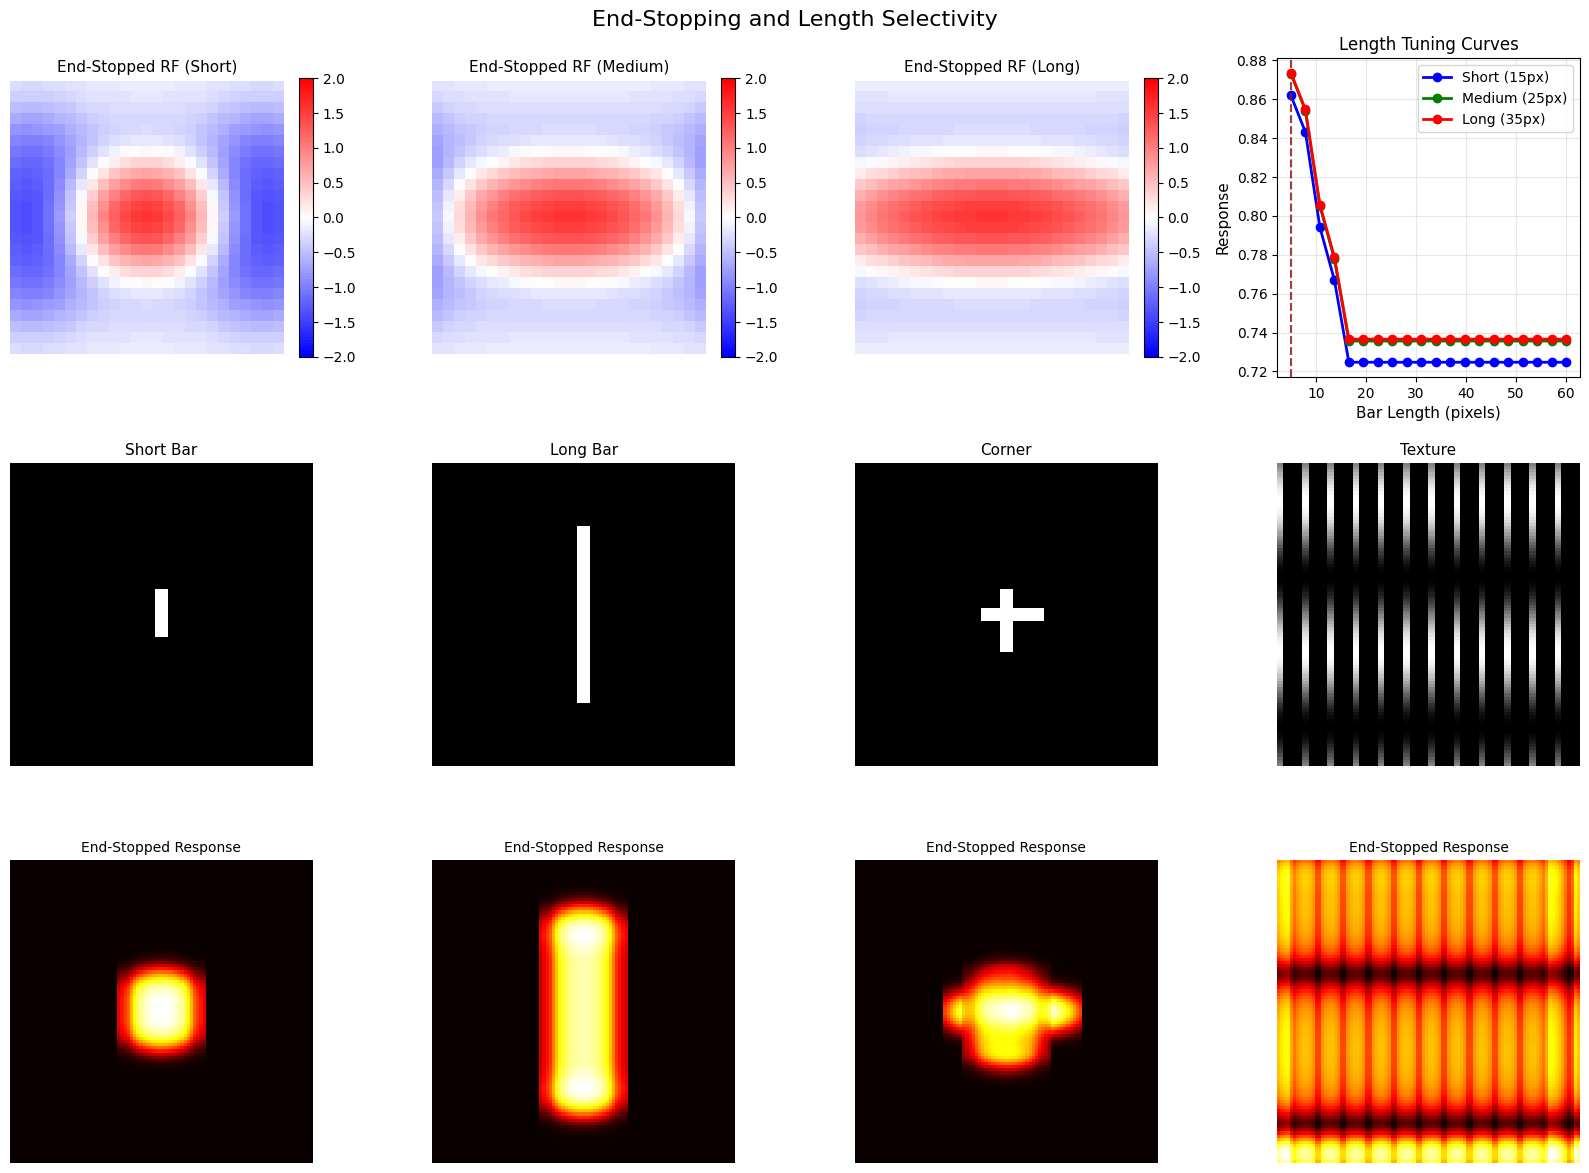

Length Selectivity Indices:
  Short (15px): LSI = 0.086
  Medium (25px): LSI = 0.085
  Long (35px): LSI = 0.085


In [ ]:
def create_end_stopped_neuron(preferred_length=20, orientation=90):
    """Create an end-stopped (hypercomplex) cell."""
    kernel_size = 25
    
    # Create the main excitatory region (center)
    x = np.arange(kernel_size) - kernel_size // 2
    y = np.arange(kernel_size) - kernel_size // 2
    X, Y = np.meshgrid(x, y)
    
    # Rotate coordinates
    theta = np.deg2rad(orientation)
    X_rot = X * np.cos(theta) + Y * np.sin(theta)
    Y_rot = -X * np.sin(theta) + Y * np.cos(theta)
    
    # Main excitatory region (oriented bar detector)
    E_center = np.exp(-(X_rot**2) / (2 * 3**2)) * np.exp(-(Y_rot**2) / (2 * (preferred_length/4)**2))
    
    # End inhibition zones
    I_ends = np.zeros_like(E_center)
    # Top end inhibition
    I_ends += np.exp(-(X_rot**2) / (2 * 5**2)) * np.exp(-((Y_rot + preferred_length/2 + 3)**2) / (2 * 3**2))
    # Bottom end inhibition
    I_ends += np.exp(-(X_rot**2) / (2 * 5**2)) * np.exp(-((Y_rot - preferred_length/2 - 3)**2) / (2 * 3**2))
    
    # Side inhibition (for orientation selectivity)
    I_sides = np.exp(-((X_rot + 6)**2) / (2 * 3**2)) + np.exp(-((X_rot - 6)**2) / (2 * 3**2))
    
    # Combine
    E_weights = E_center * 5
    I_weights = (I_ends * 3 + I_sides * 0.5 + 0.1)
    
    # Create layer
    layer = DendriteConv2d(
        in_channels=1,
        out_channels=1,
        kernel_size=kernel_size,
        padding=kernel_size//2,
        bias=False
    )
    
    with torch.no_grad():
        layer.weight_E_raw.data[0, 0] = torch.log(torch.tensor(E_weights).float() + 1e-6)
        layer.weight_I_raw.data[0, 0] = torch.log(torch.tensor(I_weights).float() + 1e-6)
    
    return layer

# Create end-stopped neurons with different preferred lengths
end_stopped_short = create_end_stopped_neuron(preferred_length=15, orientation=90)
end_stopped_medium = create_end_stopped_neuron(preferred_length=25, orientation=90)
end_stopped_long = create_end_stopped_neuron(preferred_length=35, orientation=90)

# Test length tuning
def test_length_tuning(neurons, bar_lengths, image_size=96):
    """Test response to bars of different lengths."""
    responses = []
    
    for neuron in neurons:
        neuron_responses = []
        
        for length in bar_lengths:
            # Create centered bar
            image = np.zeros((image_size, image_size))
            center_x = image_size // 2
            center_y = image_size // 2
            
            # Vertical bar
            y_start = int(center_y - length/2)
            y_end = int(center_y + length/2)
            x_start = center_x - 2
            x_end = center_x + 2
            
            # Ensure within bounds
            y_start = max(0, y_start)
            y_end = min(image_size, y_end)
            
            image[y_start:y_end, x_start:x_end] = 1.0
            
            # Get response
            img_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
            with torch.no_grad():
                response = neuron(img_tensor)
                neuron_responses.append(response.abs().max().item())
        
        responses.append(neuron_responses)
    
    return np.array(responses)

# Test different bar lengths
bar_lengths = np.linspace(5, 60, 20)
neurons = [end_stopped_short, end_stopped_medium, end_stopped_long]
length_tuning = test_length_tuning(neurons, bar_lengths)

# Create texture-selective neuron
def create_texture_neuron(spacing=8, orientation=0):
    """Create a neuron selective for periodic textures."""
    kernel_size = 25
    
    # Create periodic Gabor-like pattern
    gabor1 = create_gabor_filter(kernel_size, spacing, orientation, 0, 3)
    gabor2 = create_gabor_filter(kernel_size, spacing, orientation, np.pi, 3)
    
    # Multiple subunits for texture detection
    texture_kernel = np.abs(gabor1) + np.abs(gabor2)
    
    # Normalize
    texture_kernel = texture_kernel / texture_kernel.max()
    
    # E/I decomposition
    E_weights = texture_kernel + 0.01
    I_weights = gaussian_filter(1 - texture_kernel, sigma=2) + 0.1
    
    layer = DendriteConv2d(
        in_channels=1,
        out_channels=1,
        kernel_size=kernel_size,
        padding=kernel_size//2,
        bias=False
    )
    
    with torch.no_grad():
        layer.weight_E_raw.data[0, 0] = torch.log(torch.tensor(E_weights).float() + 1e-6)
        layer.weight_I_raw.data[0, 0] = torch.log(torch.tensor(I_weights).float() + 1e-6)
    
    return layer

# Create texture neurons
texture_fine = create_texture_neuron(spacing=6)
texture_coarse = create_texture_neuron(spacing=12)

# Visualization
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

# Show end-stopped RFs
for i, (neuron, label) in enumerate(zip(neurons, ['Short', 'Medium', 'Long'])):
    with torch.no_grad():
        E = neuron.weight_E[0, 0].numpy()
        I = neuron.weight_I[0, 0].numpy()
        rf = E - I
    
    im = axes[0, i].imshow(rf, cmap=rwb_cmap, vmin=-2, vmax=2)
    axes[0, i].set_title(f'End-Stopped RF ({label})', fontsize=11)
    axes[0, i].axis('off')
    plt.colorbar(im, ax=axes[0, i], fraction=0.046)

# Length tuning curves
ax = axes[0, 3]
labels = ['Short (15px)', 'Medium (25px)', 'Long (35px)']
colors = ['blue', 'green', 'red']

for i, (curve, label, color) in enumerate(zip(length_tuning, labels, colors)):
    ax.plot(bar_lengths, curve, 'o-', color=color, label=label, linewidth=2, markersize=6)
    # Mark preferred length
    max_idx = np.argmax(curve)
    ax.axvline(bar_lengths[max_idx], color=color, linestyle='--', alpha=0.5)

ax.set_xlabel('Bar Length (pixels)', fontsize=11)
ax.set_ylabel('Response', fontsize=11)
ax.set_title('Length Tuning Curves', fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)

# Test with different stimuli
test_stimuli = []

# Short bar
stim1 = np.zeros((96, 96))
stim1[40:55, 46:50] = 1
test_stimuli.append(('Short Bar', stim1))

# Long bar
stim2 = np.zeros((96, 96))
stim2[20:76, 46:50] = 1
test_stimuli.append(('Long Bar', stim2))

# Corner
stim3 = np.zeros((96, 96))
stim3[40:60, 46:50] = 1
stim3[46:50, 40:60] = 1
test_stimuli.append(('Corner', stim3))

# Texture
stim4 = np.zeros((96, 96))
for i in range(0, 96, 8):
    # Create vertical sine wave pattern
    sine_wave = np.sin(np.linspace(0, 4*np.pi, 96)) * 0.5 + 0.5
    # Broadcast to 2 columns
    stim4[:, i:i+2] = sine_wave[:, np.newaxis]
test_stimuli.append(('Texture', stim4))

# Show stimuli and responses
for i, (name, stim) in enumerate(test_stimuli):
    # Show stimulus
    axes[1, i].imshow(stim, cmap='gray')
    axes[1, i].set_title(name, fontsize=11)
    axes[1, i].axis('off')
    
    # Get responses
    stim_tensor = torch.tensor(stim, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    with torch.no_grad():
        # End-stopped response
        resp_medium = end_stopped_medium(stim_tensor)
        axes[2, i].imshow(resp_medium[0, 0].numpy(), cmap='hot')
        axes[2, i].set_title(f'End-Stopped Response', fontsize=10)
        axes[2, i].axis('off')

plt.suptitle('End-Stopping and Length Selectivity', fontsize=16)
plt.tight_layout()
plt.show()

# Print length selectivity indices
print("Length Selectivity Indices:")
for i, label in enumerate(labels):
    responses = length_tuning[i]
    preferred = responses.max()
    very_long = responses[-1]  # Response to longest bar
    lsi = (preferred - very_long) / (preferred + very_long)
    print(f"  {label}: LSI = {lsi:.3f}")


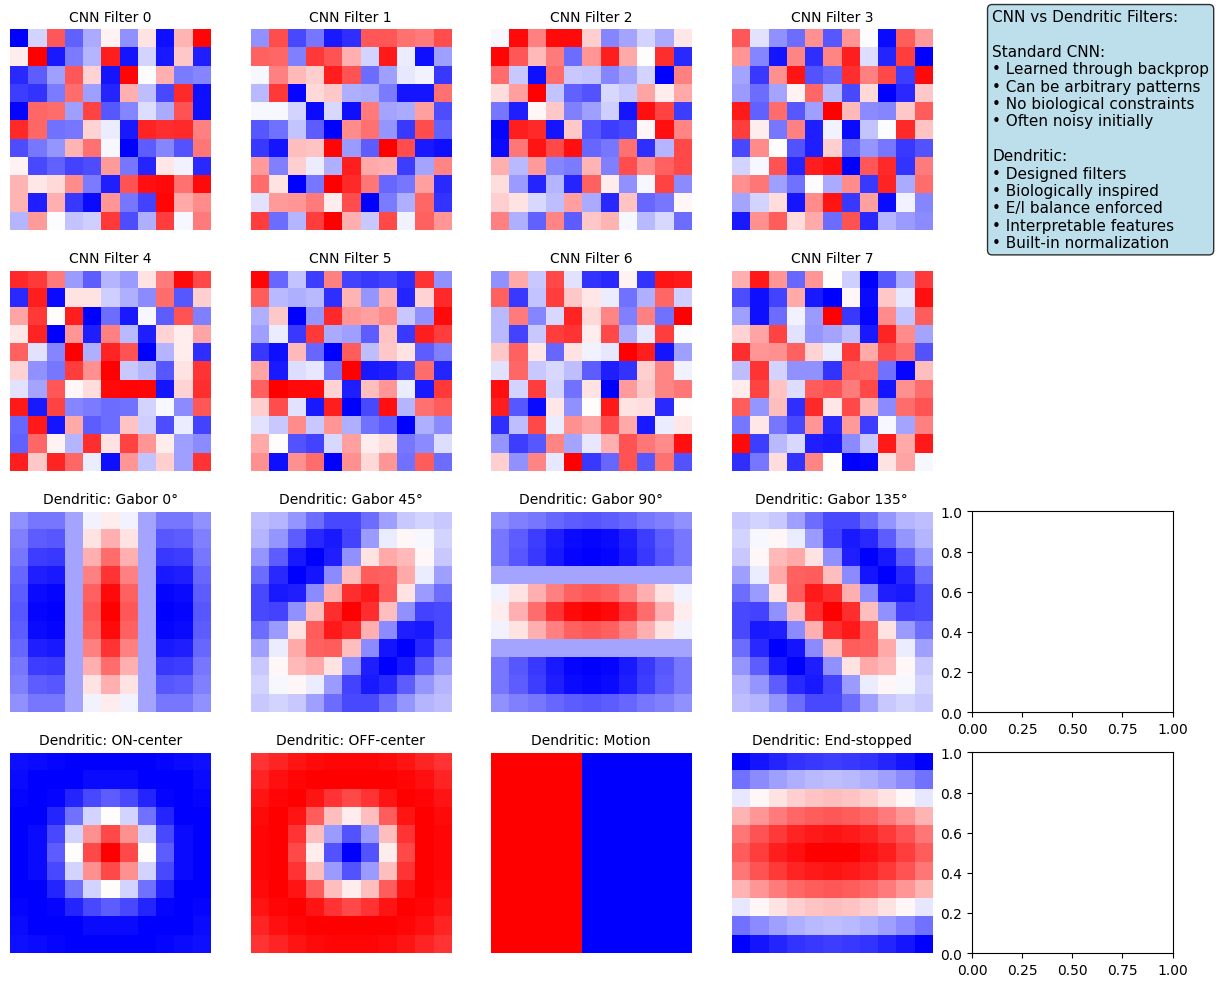

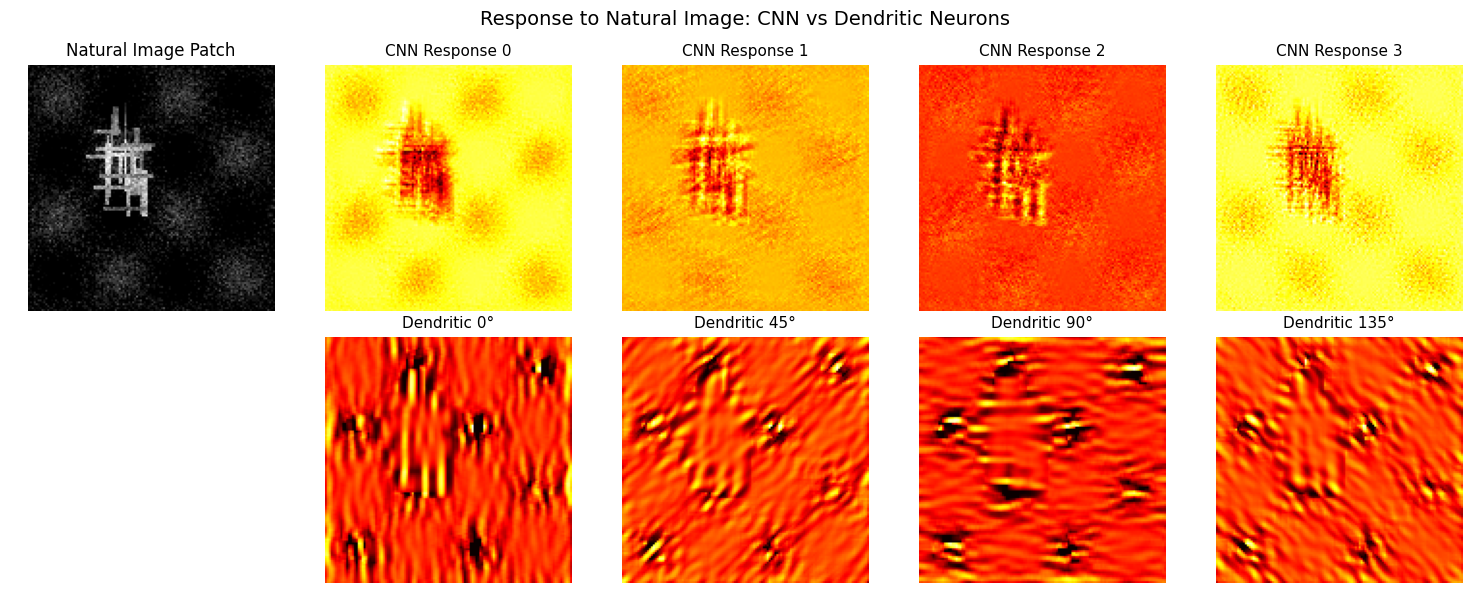

Response Statistics:
Standard CNN - Mean: -0.019, Std: 0.118
Dendritic - Mean: 0.361, Std: 0.107

Dendritic responses are normalized due to divisive inhibition!


In [ ]:
# Create standard CNN for comparison
class StandardCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=11, padding=5)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=5, padding=2)
        self.pool = nn.MaxPool2d(2, 2)
        
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        return x

# Create dendritic CNN equivalent
class DendriticVisualCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # First layer: Various oriented filters
        self.gabor_0 = create_dendritic_gabor_neuron(orientation=0)[0]
        self.gabor_45 = create_dendritic_gabor_neuron(orientation=45)[0]
        self.gabor_90 = create_dendritic_gabor_neuron(orientation=90)[0]
        self.gabor_135 = create_dendritic_gabor_neuron(orientation=135)[0]
        
        # Center-surround
        self.on_center = create_center_surround_neuron(cell_type='on-center')[0]
        self.off_center = create_center_surround_neuron(cell_type='off-center')[0]
        
        # Motion detectors
        self.motion_right = create_motion_detector('rightward')
        
        # End-stopped
        self.end_stopped = create_end_stopped_neuron(preferred_length=20)
        
        self.pool = nn.MaxPool2d(2, 2)
        
    def forward(self, x):
        # Process through different feature detectors
        features = []
        features.append(self.gabor_0(x))
        features.append(self.gabor_45(x))
        features.append(self.gabor_90(x))
        features.append(self.gabor_135(x))
        features.append(self.on_center(x))
        features.append(self.off_center(x))
        features.append(self.motion_right(x))
        features.append(self.end_stopped(x))
        
        # Stack and pool
        x = torch.cat(features, dim=1)
        x = self.pool(x)
        return x

# Initialize networks
standard_cnn = StandardCNN()
dendritic_cnn = DendriticVisualCNN()

# Compare learned vs designed filters
fig, axes = plt.subplots(4, 5, figsize=(15, 12))

# Show standard CNN filters (after random initialization)
with torch.no_grad():
    # First 8 filters from conv1
    for i in range(8):
        if i < 4:
            row, col = 0, i
        else:
            row, col = 1, i-4
        
        kernel = standard_cnn.conv1.weight[i, 0].numpy()
        im = axes[row, col].imshow(kernel, cmap=rwb_cmap)
        axes[row, col].set_title(f'CNN Filter {i}', fontsize=10)
        axes[row, col].axis('off')

# Show dendritic filters
dendritic_filters = [
    (gabor_neurons[0], 'Gabor 0°'),
    (gabor_neurons[1], 'Gabor 45°'),
    (gabor_neurons[2], 'Gabor 90°'),
    (gabor_neurons[3], 'Gabor 135°'),
    (on_center_neuron, 'ON-center'),
    (off_center_neuron, 'OFF-center'),
    (motion_detector, 'Motion'),
    (end_stopped_medium, 'End-stopped')
]

for i, (neuron, name) in enumerate(dendritic_filters):
    if i < 4:
        row, col = 2, i
    else:
        row, col = 3, i-4
    
    with torch.no_grad():
        E = neuron.weight_E[0, 0].numpy()
        I = neuron.weight_I[0, 0].numpy()
        kernel = E - I
    
    # Resize if needed for visualization
    if kernel.shape[0] > 11:
        kernel = kernel[kernel.shape[0]//2-5:kernel.shape[0]//2+6,
                       kernel.shape[1]//2-5:kernel.shape[1]//2+6]
    
    im = axes[row, col].imshow(kernel, cmap=rwb_cmap)
    axes[row, col].set_title(f'Dendritic: {name}', fontsize=10)
    axes[row, col].axis('off')

# Add comparison text
axes[0, 4].axis('off')
axes[1, 4].axis('off')
comparison_text = """CNN vs Dendritic Filters:

Standard CNN:
• Learned through backprop
• Can be arbitrary patterns
• No biological constraints
• Often noisy initially

Dendritic:
• Designed filters
• Biologically inspired
• E/I balance enforced
• Interpretable features
• Built-in normalization"""

axes[0, 4].text(0.1, 0.5, comparison_text, transform=axes[0, 4].transAxes,
               fontsize=11, verticalalignment='center',
               bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))

# Test on natural image patch
# Load or create a natural image patch
natural_patch = np.zeros((128, 128))
# Add various natural features
# Tree-like vertical structure
for i in range(20):
    x = np.random.randint(40, 60)
    y_start = np.random.randint(20, 60)
    y_end = y_start + np.random.randint(10, 30)
    width = np.random.randint(1, 4)
    natural_patch[y_start:y_end, x:x+width] = np.random.uniform(0.3, 0.8)

# Horizontal branches
for i in range(10):
    y = np.random.randint(30, 80)
    x_start = np.random.randint(30, 50)
    x_end = x_start + np.random.randint(10, 30)
    natural_patch[y:y+2, x_start:x_end] = np.random.uniform(0.4, 0.7)

# Add texture
x, y = np.ogrid[:128, :128]
texture = np.sin(0.1 * x) * np.sin(0.1 * y) * 0.2
natural_patch += texture

# Add noise
natural_patch += np.random.randn(128, 128) * 0.1
natural_patch = np.clip(natural_patch, 0, 1)

# Process through both networks
natural_tensor = torch.tensor(natural_patch, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

with torch.no_grad():
    standard_features = standard_cnn.conv1(natural_tensor)
    
    # Get dendritic features
    dendritic_features = []
    for neuron, _ in dendritic_filters[:4]:  # Just first 4 for visualization
        feat = neuron(natural_tensor)
        dendritic_features.append(feat[0, 0].numpy())

# Show results
fig2, axes2 = plt.subplots(2, 5, figsize=(15, 6))

axes2[0, 0].imshow(natural_patch, cmap='gray')
axes2[0, 0].set_title('Natural Image Patch', fontsize=12)
axes2[0, 0].axis('off')

# Standard CNN responses
for i in range(4):
    axes2[0, i+1].imshow(standard_features[0, i].numpy(), cmap='hot')
    axes2[0, i+1].set_title(f'CNN Response {i}', fontsize=11)
    axes2[0, i+1].axis('off')

# Dendritic responses
axes2[1, 0].axis('off')
for i in range(4):
    axes2[1, i+1].imshow(dendritic_features[i], cmap='hot')
    axes2[1, i+1].set_title(f'Dendritic {i*45}°', fontsize=11)
    axes2[1, i+1].axis('off')

plt.suptitle('Response to Natural Image: CNN vs Dendritic Neurons', fontsize=14)
plt.tight_layout()
plt.show()

# Compute response statistics
print("Response Statistics:")
print(f"Standard CNN - Mean: {standard_features.mean():.3f}, Std: {standard_features.std():.3f}")
print(f"Dendritic - Mean: {np.mean(dendritic_features):.3f}, Std: {np.std(dendritic_features):.3f}")
print(f"\nDendritic responses are normalized due to divisive inhibition!")
